# Neuro-Symbolic Intrusion Detection for Resource-Constrained OT/ICS/SCADA Environments (Revision 1)

**GRU + shallow decision tree fusion for DoS/DDoS detection, evaluated with capture-aware splits.**

### Pipeline
- **Data**: records are kept in original capture order; windows of length L are built inside each capture before partitioning
- **Labels**: benign = 0, DoS/DDoS families = 1; other attack families are set aside and only used for an alert-rate check
- **Splits**: time-blocked (70/15/15 per capture with a purge gap) and capture-held-out
- **Neural Component**: 2-layer GRU over the window
- **Symbolic Component**: shallow CART tree on the last record of the window (scaled features, training windows only)
- **Fusion**: alpha x neural + (1 - alpha) x symbolic, with alpha and threshold selected on validation
- **Operating points**: FPR budget (Neyman-Pearson), expected cost, and F1, applied in the same way to every model
- **Statistics**: moving-block bootstrap, cluster bootstrap over captures, stride-L Wilson check, prevalence analysis

### Datasets Used
- **CIC-DDoS2019** (dhoogla parquet version)
- **Edge-IIoTset** (DNN-EdgeIIoT-dataset.csv)
- **CICIoT23**

### Running
Use a GPU runtime (Runtime > Change runtime type > T4 GPU) and run the cells in order. Results are saved to
`OUT_DIR` on Google Drive and finished runs are skipped, so after a disconnect simply run all cells again.
CELL 19 (statistics), CELL 20 (tables) and CELL 21 (figures) only read the saved results and can be run on
their own after CELLS 0 to 11.

In [1]:
# CELL 0: Environment Setup (Colab or local)
print("CELL 0: Environment Setup (Colab or local)\n")
#   Colab: mounts Drive, downloads the three datasets with kagglehub, and switches the working
#   directory to OUT_DIR on Drive so all outputs survive a runtime disconnect.
#   Kaggle login: add KAGGLE_USERNAME / KAGGLE_KEY in Colab Secrets (key icon, enable notebook
#   access), or log in when the prompt appears.
#   Locally (or to use files you already have on Drive), set the paths in LOCAL_PATHS instead.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Paths you already have (leave as None to download from Kaggle in Colab).
#   cic_ddos : folder containing the dhoogla CIC-DDoS2019 *.parquet files (version 3)
#   edge_iot : folder of the Edge-IIoTset dataset (the one that contains 'Selected dataset for ML and DL')
#   ciciot23 : either a folder of per-capture CSVs (e.g. MERGED_CSV / part-*.csv),
#              or a folder with train/train.csv, validation/validation.csv, test/test.csv
LOCAL_PATHS = {
    "cic_ddos": None,
    "edge_iot": None,
    "ciciot23": None,
}

# Kaggle handles tried in order (pinned version first, then latest). If a download fails, the slug is
# searched on Kaggle; you can also paste the owner/slug from the dataset URL at the front of the list.
KAGGLE = {
    "cic_ddos": ("cicddos2019", 3, ["dhoogla/cicddos2019"]),
    "edge_iot": ("edgeiiotset-cyber-security-dataset-of-iot-iiot", 5,
                 ["mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"]),
    # CICIoT2023: use a copy that keeps the per-capture CSV files if you can (needed for the
    # capture-held-out split). Put your preferred handle first.
    "ciciot23": ("ciciot2023", None, ["akashdogra/cic-iot-2023"]),
}

if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/NeuroSymbolicIDS_rev1")
    except Exception as e:
        print(f"   WARNING: Drive mount failed ({type(e).__name__}: {e}); using local directory.")
        OUT_DIR = Path("/content/NeuroSymbolicIDS_rev1")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub", "xgboost"], check=False)
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    if any(LOCAL_PATHS[k] is None for k in LOCAL_PATHS):
        import kagglehub
        try:
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        except Exception:
            kagglehub.login()

        def kaggle_search(slug):
            try:
                r = subprocess.run(["kaggle", "datasets", "list", "-s", slug.replace("-", " "), "--csv"],
                                   capture_output=True, text=True, timeout=120)
            except Exception:
                return []
            rows = [l.split(",")[0] for l in r.stdout.splitlines()[1:] if l.strip()]
            return [h for h in rows if h.split("/")[-1] == slug] + [h for h in rows if h.split("/")[-1] != slug]

        def fetch(slug, ver, cands):
            tried = []
            for h in cands + [c for c in kaggle_search(slug) if c not in cands]:
                refs = ([f"{h}/versions/{ver}"] if ver else []) + [h]
                for ref in refs:
                    try:
                        p = Path(kagglehub.dataset_download(ref))
                        if ver and ref == h:
                            print(f"   WARNING: {h} version {ver} unavailable - using latest version")
                        return h, p
                    except Exception as e:
                        tried.append(f"{ref} ({type(e).__name__})")
            raise RuntimeError(f"could not download '{slug}'. Tried: {tried}. Put the correct owner/slug "
                               f"from the Kaggle URL first in KAGGLE['...'], or set LOCAL_PATHS.")

        for key, (slug, ver, cands) in KAGGLE.items():
            if LOCAL_PATHS[key] is None:
                handle, root = fetch(slug, ver, cands)
                LOCAL_PATHS[key] = str(root)
                size = sum(f.stat().st_size for f in root.rglob('*') if f.is_file()) / 1e6
                print(f"   {key:9s} {handle:65s} -> {root}  ({size:,.0f} MB)")
else:
    OUT_DIR = Path(os.environ.get("NSIDS_OUT", "./NeuroSymbolicIDS_rev1"))
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for key in LOCAL_PATHS:
        env = os.environ.get(f"NSIDS_{key.upper()}")
        if env:
            LOCAL_PATHS[key] = env

os.chdir(OUT_DIR)
print(f"outputs -> {Path.cwd()}")
for k, v in LOCAL_PATHS.items():
    print(f"   {k:9s}: {v}")
print("CELL 0 complete")

CELL 0: Environment Setup (Colab or local)

Mounted at /content/drive


100%|██████████| 28.7M/28.7M [00:00<00:00, 122MB/s]

Extracting files...


   cic_ddos  dhoogla/cicddos2019                                               -> /root/.cache/kagglehub/datasets/dhoogla/cicddos2019/versions/3  (35 MB)
Using Colab cache for faster access to the 'edgeiiotset-cyber-security-dataset-of-iot-iiot' dataset.
   edge_iot  mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot -> /kaggle/input/edgeiiotset-cyber-security-dataset-of-iot-iiot  (11,249 MB)


100%|██████████| 2.77G/2.77G [00:41<00:00, 72.0MB/s]

Extracting files...


   ciciot23  akashdogra/cic-iot-2023                                           -> /root/.cache/kagglehub/datasets/akashdogra/cic-iot-2023/versions/1  (13,754 MB)
outputs -> /content/drive/MyDrive/NeuroSymbolicIDS_rev1
   cic_ddos : /root/.cache/kagglehub/datasets/dhoogla/cicddos2019/versions/3
   edge_iot : /kaggle/input/edgeiiotset-cyber-security-dataset-of-iot-iiot
   ciciot23 : /root/.cache/kagglehub/datasets/akashdogra/cic-iot-2023/versions/1
CELL 0 complete


In [2]:
# CELL 1: Global Configuration
print("CELL 1: Global Configuration\n")
import numpy as np

CFG = dict(
    DATASETS=["cic_ddos", "edge_iot", "ciciot23"],
    # Partitioning schemes
    #   time_blocked     : per capture, contiguous 70/15/15 blocks with a purge gap
    #   capture_held_out : whole captures assigned to one partition
    #   record_level     : the ORIGINAL shuffled protocol (kept only for the protocol-effect table)
    SCHEMES=["time_blocked", "capture_held_out"],
    SEQ_LEN=16,              # window length L (used for training AND evaluation)
    STRIDE=1,                # window stride s
    PURGE=None,              # purge gap in records at each partition boundary (None -> SEQ_LEN)
    TRAIN_FRAC=0.70, VAL_FRAC=0.15,
    TRAIN_ATTACK_SHARE=0.30,  # under-sample attack windows in TRAIN only, down to this share
    UNDERSAMPLE={"cic_ddos": True, "edge_iot": False, "ciciot23": True},
    MAX_TRAIN_WINDOWS=1_500_000,  # random cap on training windows after under-sampling (None = no cap)
    MAX_ROWS_PER_FILE=None,       # contiguous head of each file (None = all); preserves order
    CICIOT_MAX_FILES=40,          # per-capture CICIoT23: number of capture files used (seeded choice)
    CIC_USE_DAY_SPLIT=True,       # CIC-DDoS capture-held-out: train/val on day-1 files, test on day-2 files
    CHO_FOLDS=3,                  # capture-held-out folds for the other datasets
    EDGE_SOURCE="selected",       # 'selected' = DNN-EdgeIIoT-dataset.csv, 'raw' = per-scenario CSVs
    # GRU hyperparameters
    HIDDEN=64, LAYERS=2, DROPOUT=0.25, BATCH=256, EPOCHS=20, LR=1e-3, WEIGHT_DECAY=1e-4,
    PATIENCE=4, USE_LAYERNORM=True,
    # Symbolic branch (CART), per dataset
    #   TREE_INPUT = "last"         : the last record of the window (as in the paper)
    #   TREE_INPUT = "window_stats" : last record + mean/std/min/max of each feature over the window.
    #                                 Rules stay readable (e.g. "mean16(Flow IAT Mean) <= 120 us") and the
    #                                 tree usually gets much stronger; the paper text must then say so.
    TREE_INPUT=os.environ.get("NSIDS_TREE_INPUT", "last"),
    TREE={"cic_ddos": dict(max_depth=5, min_samples_split=100, min_samples_leaf=40),
          "edge_iot": dict(max_depth=2, min_samples_split=100, min_samples_leaf=80),
          "ciciot23": dict(max_depth=5, min_samples_split=100, min_samples_leaf=40)},
    # Operating points
    ALPHA_GRID=np.round(np.linspace(0, 1, 41), 3),
    TAU_GRID_F1=np.round(np.linspace(0.05, 0.95, 37), 3),   # paper's grid, F1 criterion only
    TAU_GRID_COST=np.round(np.linspace(0.001, 0.999, 999), 3),
    NP_BETAS=[0.001, 0.005, 0.01],
    HEADLINE_BETA=0.01,
    COST_RATIOS=[1, 10, 100], PREVALENCES=[0.001, 0.01, 0.05],
    R_DEC=340.0,              # decisions per second for alerts/hour (testbed sustained flow rate)
    # Statistics
    BOOT_B=2000, MBB_BLOCKS=[16, 64, 256, 1024], MBB_HEADLINE_BLOCK=256,
    # Experiments
    SEEDS=list(range(42, 52)),
    L_SWEEP=[1, 4, 8, 16, 32, 64],
    HIDDEN_SWEEP=[32, 64, 128], LAYERS_SWEEP=[1, 2],
    STRIDE_SWEEP=[1, 4, 16],
    DEPTH_SWEEP=[2, 3, 5, 8, None],
    QUICK=os.environ.get("NSIDS_QUICK") == "1",  # True = tiny smoke test (few epochs, capped data, 2 seeds)
)
if CFG["QUICK"]:
    CFG.update(EPOCHS=2, MAX_TRAIN_WINDOWS=50_000, MAX_ROWS_PER_FILE=60_000, SEEDS=[42, 43],
               BOOT_B=200, CICIOT_MAX_FILES=6, L_SWEEP=[1, 16], HIDDEN_SWEEP=[64], LAYERS_SWEEP=[2],
               STRIDE_SWEEP=[1, 16])
if CFG["PURGE"] is None:
    CFG["PURGE"] = CFG["SEQ_LEN"]
print("Configuration loaded. QUICK =", CFG["QUICK"])

CELL 1: Global Configuration

Configuration loaded. QUICK = False


In [3]:
# CELL 2: Imports & Helpers
print("CELL 2: Imports & Helpers\n")
import json, time, re, gc, hashlib, platform, warnings, pickle, math
from dataclasses import dataclass, field
import pandas as pd
import torch
import torch.nn as nn
import sklearn
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RES = Path("results"); RES.mkdir(exist_ok=True)
ART = Path("artefacts"); ART.mkdir(exist_ok=True)

try:
    import xgboost as xgb
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

ENV = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__,
           numpy=np.__version__, pandas=pd.__version__, xgboost=(xgb.__version__ if HAVE_XGB else None),
           device=str(DEVICE), gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
           platform=platform.platform())
json.dump(ENV, open(RES / "environment.json", "w"), indent=2)
print(json.dumps(ENV, indent=2))


def set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def norm_name(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())


def jdump(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    def conv(o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        if isinstance(o, Path): return str(o)
        return str(o)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=conv)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

print("CELL 2 complete")

CELL 2: Imports & Helpers

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "sklearn": "1.6.1",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "xgboost": "3.4.1",
  "device": "cuda",
  "gpu": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}
CELL 2 complete


In [4]:
# CELL 3: Feature Governance & Label Mapping
print("CELL 3: Feature Governance & Label Mapping\n")
#
# Columns are dropped by exact normalised name together with the reason; the list is saved to
# results/<dataset>/feature_governance.csv
DENY = {
    # labels
    "label": "label", "attacklabel": "label", "attacktype": "label", "class": "label",
    "category": "label", "subcategory": "label", "target": "label",
    # identifiers / addresses / time
    "flowid": "identifier", "srcip": "address", "dstip": "address", "sourceip": "address",
    "destinationip": "address", "ipsrchost": "address", "ipdsthost": "address",
    "arpsrcprotoipv4": "address", "arpdstprotoipv4": "address",
    "timestamp": "time", "frametime": "time", "icmptransmittimestamp": "time",
    "unnamed0": "row index", "simillarhttp": "dataset artefact", "inbound": "dataset artefact",
    # ports
    "srcport": "port", "dstport": "port", "sourceport": "port", "destinationport": "port",
    "tcpsrcport": "port", "tcpdstport": "port", "udpport": "port", "httptlsport": "port",
    # per-connection counters, checksums and sequence numbers (session-unique, shortcut-prone)
    "tcpchecksum": "checksum", "icmpchecksum": "checksum", "tcpseq": "sequence number",
    "tcpack": "sequence number", "tcpackraw": "sequence number", "udpstream": "stream index",
    "mbtcptransid": "transaction id", "icmpseqle": "sequence number",
    # payload / free text
    "httpfiledata": "payload", "httprequestfulluri": "payload", "httprequesturiquery": "payload",
    "tcpoptions": "payload", "tcppayload": "payload", "mqttmsg": "payload", "dnsqryname": "payload",
    "httpreferer": "payload", "mqtttopic": "payload",
}
LABEL_CANDIDATES = ["label", "attacktype", "class", "category"]


def map_label(raw, dataset):
    """Return 0 (benign), 1 (DoS/DDoS) or -1 (other attack family, excluded)."""
    s = str(raw).strip().lower()
    if s in ("", "nan") or "benign" in s or "normal" in s or s == "0":
        return 0
    if dataset == "cic_ddos":
        return 1                               # every CIC-DDoS2019 attack class is a DoS variant
    if s.startswith("ddos") or s.startswith("dos"):
        return 1                               # Edge-IIoTset DDoS_*, CICIoT23 DDoS-*/DoS-*
    return -1


def family_name(raw):
    return str(raw).strip()


UNIT_HINTS = [  # CICFlowMeter conventions, used to annotate exported rules
    (r"duration|iat", "us"), (r"bytes/s|byts/s|bytes_s", "B/s"), (r"packets/s|pkts/s|rate", "1/s"),
    (r"length|len|size|bytes|byts", "B"), (r"count|cnt|flag|number|num|tot|packets|pkts", "count"),
]


def unit_of(feat):
    f = feat.lower()
    for pat, u in UNIT_HINTS:
        if re.search(pat, f):
            return u
    return ""

print("CELL 3 complete")

CELL 3: Feature Governance & Label Mapping

CELL 3 complete


In [5]:
# CELL 4: Dataset Loaders
print("CELL 4: Dataset Loaders\n")
@dataclass
class Capture:
    name: str
    df: pd.DataFrame          # numeric candidate features (float32), original order
    raw_label: pd.Categorical  # original label strings (categorical, original order)
    group: str = ""           # e.g. 'day1' / 'day2' for CIC-DDoS
    id_df: pd.DataFrame = None  # numeric identifier columns kept ONLY for the shortcut audit
    y: np.ndarray = None      # mapped labels: 0 benign, 1 DoS/DDoS, -1 excluded family


def _split_columns(df):
    label_col = None
    for cand in LABEL_CANDIDATES:
        for c in df.columns:
            if norm_name(c) == cand:
                label_col = c; break
        if label_col: break
    feats, ids, governance = [], [], []
    for c in df.columns:
        n = norm_name(c)
        if n in DENY:
            governance.append((c, "removed", DENY[n]))
            if DENY[n] in ("port", "identifier", "address", "time", "checksum", "sequence number",
                           "stream index", "transaction id", "row index") and pd.api.types.is_numeric_dtype(df[c]):
                ids.append(c)
        else:
            feats.append(c)
    return label_col, feats, ids, governance


def _to_numeric_frame(df, cols):
    out = {}
    for c in cols:
        s = df[c]
        if not pd.api.types.is_numeric_dtype(s):
            s = pd.to_numeric(s, errors="coerce")
        out[c] = s.astype("float32")
    out = pd.DataFrame(out)
    out = out.replace([np.inf, -np.inf], np.nan)
    return out


SKIP_ON_READ = {"payload", "address"}   # long text columns are never features, so they are not loaded


def _read(f, nrows=None):
    """Reads one file with low memory use: text-only columns are skipped and numbers are read as float32."""
    if str(f).endswith(".parquet"):
        df = pd.read_parquet(f)
        df = df.iloc[:nrows] if nrows else df
        for c in df.columns:
            if pd.api.types.is_float_dtype(df[c]):
                df[c] = df[c].astype("float32")
        return df
    head = pd.read_csv(f, nrows=2000, low_memory=False)
    use = [c for c in head.columns if DENY.get(norm_name(c)) not in SKIP_ON_READ]
    keep_text = {c for c in use if norm_name(c) in LABEL_CANDIDATES or norm_name(c) in ("frametime", "attacklabel")}
    dtypes = {c: "float32" for c in use if c not in keep_text and pd.api.types.is_numeric_dtype(head[c])}
    for c in keep_text:
        dtypes[c] = "category"
    # read in chunks of 500k rows so the parser never holds the whole text file in memory
    try:
        chunks = [ch for ch in pd.read_csv(f, usecols=use, dtype=dtypes, nrows=nrows, chunksize=500_000)]
    except (ValueError, TypeError):
        chunks = []
        for ch in pd.read_csv(f, usecols=use, nrows=nrows, chunksize=500_000, low_memory=False):
            for c in ch.columns:
                if c in keep_text:
                    ch[c] = ch[c].astype(str).astype("category")
                elif DENY.get(norm_name(c)) is None:
                    ch[c] = pd.to_numeric(ch[c], errors="coerce").astype("float32")
            chunks.append(ch)
    df = pd.concat(chunks, ignore_index=True) if len(chunks) > 1 else chunks[0]
    del chunks
    for c in keep_text:   # categories may differ between chunks
        if df[c].dtype != "category":
            df[c] = df[c].astype(str).astype("category")
    return df


def make_capture(df, name, dataset, group="", label_override=None):
    label_col, feats, ids, gov = _split_columns(df)
    if label_override is not None:
        raw = pd.Categorical([label_override] * len(df))
    elif label_col is None:
        raise ValueError(f"no label column in {name}: {list(df.columns)[:10]}...")
    else:
        col = df[label_col]
        if not isinstance(col.dtype, pd.CategoricalDtype):
            col = col.astype(str).astype("category")
        stripped = [str(c).strip() for c in col.cat.categories] + ["nan"]
        new_cats = list(dict.fromkeys(stripped))
        remap = np.array([new_cats.index(c) for c in stripped], dtype=np.int32)
        codes = col.cat.codes.values.astype(np.int32)
        codes = np.where(codes < 0, len(stripped) - 1, codes)
        raw = pd.Categorical.from_codes(remap[codes], new_cats)
    X = _to_numeric_frame(df, feats)
    X = X.loc[:, X.notna().any(axis=0)]      # drop columns that are entirely non-numeric
    dropped_nonnum = [c for c in feats if c not in X.columns]
    gov += [(c, "removed", "non-numeric") for c in dropped_nonnum]
    idf = _to_numeric_frame(df, ids) if ids else None
    lut = np.array([map_label(c, dataset) for c in raw.categories], dtype=np.int8)
    y = lut[raw.codes] if len(lut) else np.zeros(len(df), np.int8)
    return Capture(name, X.fillna(0.0), raw, group, idf, y), gov


def load_cic_ddos():
    root = Path(LOCAL_PATHS["cic_ddos"])
    files = sorted(list(root.rglob("*.parquet")) + list(root.rglob("*.csv")))
    caps, gov = [], []
    for f in files:
        df = _read(f, CFG["MAX_ROWS_PER_FILE"])
        group = "day1" if "train" in f.stem.lower() else ("day2" if "test" in f.stem.lower() else "")
        c, g = make_capture(df, f.stem, "cic_ddos", group)
        caps.append(c); gov += g
    return caps, gov


EDGE_RAW_MAP = [("udp", "DDoS_UDP"), ("icmp", "DDoS_ICMP"), ("http", "DDoS_HTTP"), ("tcp", "DDoS_TCP"),
                ("syn", "DDoS_TCP")]


def load_edge_iot():
    root = Path(LOCAL_PATHS["edge_iot"])
    caps, gov = [], []
    if CFG["EDGE_SOURCE"] == "raw":
        # per-scenario CSVs: 'Normal traffic/**.csv' and 'Attack traffic/*.csv'
        for f in sorted(root.rglob("*.csv")):
            parts = [p.lower() for p in f.parts]
            if any("selected" in p for p in parts):
                continue
            if any("normal" in p for p in parts):
                lab = "Normal"
            else:
                stem = f.stem.lower()
                lab = next((v for k, v in EDGE_RAW_MAP if "ddos" in stem and k in stem), f.stem)
            df = _read(f, CFG["MAX_ROWS_PER_FILE"])
            c, g = make_capture(df, f.stem, "edge_iot", label_override=lab)
            caps.append(c); gov += g
        return caps, gov
    # 'selected' merged file: DNN-EdgeIIoT-dataset.csv only (ML-EdgeIIoT overlaps it -> not used)
    hits = sorted(root.rglob("DNN-EdgeIIoT-dataset.csv"))
    if not hits:
        raise FileNotFoundError(f"DNN-EdgeIIoT-dataset.csv not found under {root}")
    df = _read(hits[0], None)
    # one capture per traffic type, records in file order (sorted by frame.time when parseable)
    tcol = next((c for c in df.columns if norm_name(c) == "frametime"), None)
    if tcol is not None:
        t = pd.to_datetime(df[tcol].astype(str).str.strip(), errors="coerce")
        if t.notna().mean() > 0.9:
            df = df.assign(_t=t).sort_values("_t", kind="stable").drop(columns="_t")
    lab = next(c for c in df.columns if norm_name(c) == "attacktype")
    for typ, sub in df.groupby(lab, sort=True):
        if CFG["MAX_ROWS_PER_FILE"]:
            sub = sub.iloc[:CFG["MAX_ROWS_PER_FILE"]]
        c, g = make_capture(sub.reset_index(drop=True), f"type_{typ}", "edge_iot")
        caps.append(c); gov += g
    return caps, gov


def load_ciciot23():
    root = Path(LOCAL_PATHS["ciciot23"])
    split_files = [root / "train" / "train.csv", root / "validation" / "validation.csv", root / "test" / "test.csv"]
    caps, gov = [], []
    if all(p.exists() for p in split_files):
        print("   CICIoT23: pre-split train/validation/test CSVs found. These are record-level splits;"
              " each file is treated as one capture and the order audit will show whether any temporal"
              " order survives. Per-capture CSVs are preferred for the capture-held-out scheme.")
        for p in split_files:
            df = _read(p, CFG["MAX_ROWS_PER_FILE"])
            c, g = make_capture(df, p.stem, "ciciot23")
            caps.append(c); gov += g
        return caps, gov
    files = sorted(root.rglob("*.csv"))
    if not files:
        raise FileNotFoundError(f"no CSVs under {root}")
    rng = np.random.default_rng(12345)
    if CFG["CICIOT_MAX_FILES"] and len(files) > CFG["CICIOT_MAX_FILES"]:
        files = sorted(rng.choice(files, CFG["CICIOT_MAX_FILES"], replace=False).tolist())
    for f in files:
        df = _read(f, CFG["MAX_ROWS_PER_FILE"])
        c, g = make_capture(df, Path(f).stem, "ciciot23")
        caps.append(c); gov += g
    return caps, gov


LOADERS = {"cic_ddos": load_cic_ddos, "edge_iot": load_edge_iot, "ciciot23": load_ciciot23}
_CACHE = {}


def load_dataset(name):
    if name in _CACHE:
        return _CACHE[name]
    _CACHE.clear(); gc.collect()          # keep only one dataset in RAM at a time
    t0 = time.time()
    caps, gov = LOADERS[name]()
    # common feature set across captures (intersection, in first-capture order)
    common = [c for c in caps[0].df.columns if all(c in k.df.columns for k in caps)]
    for k in caps:
        k.df = k.df[common]
    id_common = None
    if all(k.id_df is not None for k in caps):
        id_common = [c for c in caps[0].id_df.columns if all(c in k.id_df.columns for k in caps)]
    for k in caps:
        k.id_df = k.id_df[id_common] if id_common else None
    gov_df = pd.DataFrame(gov, columns=["column", "action", "reason"]).drop_duplicates()
    gov_df = pd.concat([gov_df, pd.DataFrame({"column": common, "action": "candidate", "reason": ""})])
    (RES / name).mkdir(exist_ok=True)
    gov_df.to_csv(RES / name / "feature_governance.csv", index=False)
    print(f"[{name}] {len(caps)} captures, {sum(len(k.df) for k in caps):,} records, "
          f"{len(common)} candidate features ({time.time()-t0:.0f}s)")
    _CACHE[name] = (caps, common)
    return caps, common

print("CELL 4 complete")

CELL 4: Dataset Loaders

CELL 4 complete


In [6]:
# CELL 5: Temporal Order Audit & Class Counts
print("CELL 5: Temporal Order Audit & Class Counts\n")
#   For each capture, compares how often adjacent records share a label with what a random order would
#   give. If the two match, the file carries no temporal order and GRU windows over it are not temporal.
def order_audit(name):
    caps, _ = load_dataset(name)
    rows = []
    for k in caps:
        y = k.y
        keep = y >= 0
        yk = y[keep]
        if len(yk) < 3:
            continue
        p = yk.mean()
        adj = float(np.mean(yk[1:] == yk[:-1]))
        exp = float(p ** 2 + (1 - p) ** 2)
        x = k.df.values[:1_000_000][keep[:1_000_000]].astype(np.float32)   # first 1M records are enough
        x = (x - x.mean(0)) / (x.std(0) + 1e-9)
        ac = float(np.nanmean(np.mean(x[1:] * x[:-1], axis=0))) if len(x) > 2 else np.nan
        rows.append(dict(capture=k.name, group=k.group, records=int(len(y)), benign=int((y == 0).sum()),
                         dos=int((y == 1).sum()), excluded=int((y < 0).sum()),
                         adj_label_agreement=round(adj, 4), expected_if_random=round(exp, 4),
                         mean_lag1_feature_autocorr=round(ac, 4)))
    df = pd.DataFrame(rows)
    df.to_csv(RES / name / "order_audit_and_counts.csv", index=False)
    fam = pd.concat([pd.Series(np.asarray(k.raw_label)) for k in caps]).value_counts()
    fam = fam.rename_axis("family").reset_index(name="records")
    fam["mapped"] = fam["family"].map(lambda v: {0: "benign", 1: "DoS/DDoS", -1: "excluded"}[map_label(v, name)])
    fam.to_csv(RES / name / "class_counts.csv", index=False)
    return df, fam

print("CELL 5 complete")

CELL 5: Temporal Order Audit & Class Counts

CELL 5 complete


In [7]:
# CELL 6: Partitioning, Windows, Scaling & Under-sampling
print("CELL 6: Partitioning, Windows, Scaling & Under-sampling\n")
@dataclass
class Prepared:
    name: str; scheme: str; seed: int; L: int
    X: np.ndarray                 # scaled records (float32), all kept + excluded records
    y: np.ndarray                 # record labels (0/1, -1 for excluded)
    feats: list
    scaler: RobustScaler
    ends: dict                    # partition -> window end indices into X
    run_of_end: dict              # partition -> run id per window (for block bootstrap)
    cap_of_end: dict              # partition -> capture id per window (for cluster bootstrap)
    cap_names: list
    id_X: np.ndarray = None       # identifier columns (audit only)
    id_feats: list = None
    manifest: dict = field(default_factory=dict)


PCODE = {"train": 0, "val": 1, "test": 2}


def _segments(mask):
    """Contiguous [start, end) runs where mask is True."""
    if len(mask) == 0:
        return []
    d = np.diff(np.concatenate([[0], mask.astype(np.int8), [0]]))
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))


def _assign_captures(caps, name, seed, fold):
    """capture_held_out: returns dict capture_index -> partition ('train'/'val'/'test'/'trainval')."""
    if name == "cic_ddos" and CFG["CIC_USE_DAY_SPLIT"] and {k.group for k in caps} >= {"day1", "day2"}:
        return {i: ("test" if k.group == "day2" else "trainval") for i, k in enumerate(caps)}
    sizes = np.array([len(k.df) for k in caps])
    has = [set(np.unique(k.y[k.y >= 0]).tolist()) for k in caps]
    rng = np.random.default_rng(seed * 100 + fold)
    for _ in range(200):
        order = rng.permutation(len(caps))
        part, tot = {}, sizes.sum()
        acc = {"test": 0, "val": 0}
        for i in order:
            if acc["test"] < (1 - CFG["TRAIN_FRAC"] - CFG["VAL_FRAC"]) * tot:
                part[i] = "test"; acc["test"] += sizes[i]
            elif acc["val"] < CFG["VAL_FRAC"] * tot:
                part[i] = "val"; acc["val"] += sizes[i]
            else:
                part[i] = "train"
        ok = True
        for p_ in ("train", "val", "test"):
            members = [i for i in part if part[i] == p_]
            if not members or not {0, 1} <= set().union(*[has[i] for i in members]):
                ok = False
        if ok:
            return part
    return None


def prepare(name, scheme, seed, L=None, stride=None, fold=0, L_for_ends=None, positive_all=False):
    L = L or CFG["SEQ_LEN"]; stride = stride or CFG["STRIDE"]
    Le = max(L, L_for_ends or L)             # windows need Le-1 records of history inside their run
    caps, feats0 = load_dataset(name)
    purge = CFG["PURGE"]
    labs = []
    for k in caps:
        y = k.y.copy()
        if positive_all:
            y[y < 0] = 1                      # original protocol: every attack = 1
        labs.append(y)

    # ---- record-level partition labels ----
    part_rec = []
    if scheme == "record_level":
        rng = np.random.default_rng(seed)
        offs = np.cumsum([0] + [len(k.df) for k in caps])
        ally = np.concatenate(labs)
        from sklearn.model_selection import train_test_split
        idx = np.arange(len(ally))
        keep = idx[ally >= 0]
        tr, te = train_test_split(keep, test_size=1 - CFG["TRAIN_FRAC"], stratify=ally[keep], random_state=seed)
        va, te = train_test_split(te, test_size=(1 - CFG["TRAIN_FRAC"] - CFG["VAL_FRAC"]) / (1 - CFG["TRAIN_FRAC"]),
                                  stratify=ally[te], random_state=seed)
        p = np.full(len(ally), -1, dtype=np.int8); p[tr] = 0; p[va] = 1; p[te] = 2
        # shuffle records inside each partition, as the original notebook effectively did
        order = np.concatenate([rng.permutation(np.where(p == c)[0]) for c in (0, 1, 2)]
                               + [np.where(ally < 0)[0]])
        bigcap = np.concatenate([np.full(len(k.df), i, dtype=np.int32) for i, k in enumerate(caps)])[order]
        bigX = np.concatenate([k.df.values for k in caps]).astype(np.float32, copy=False)
        caps = [Capture(k.name, None, None, k.group) for k in caps]   # release the cached frames
        _CACHE.clear(); gc.collect()
        bigX = bigX[order]
        bigy = ally[order]; bigp = p[order]
        caps_iter = [(bigX, bigy, bigp, bigcap, None)]
    else:
        if scheme == "capture_held_out":
            assign = _assign_captures(caps, name, seed, fold)
            if assign is None:
                raise RuntimeError(f"{name}: no capture-held-out assignment has both classes in every "
                                   f"partition (too few captures, e.g. one capture per class).")
        caps_iter = []
        for i, k in enumerate(caps):
            n = len(k.df)
            pos = np.arange(n) / max(n, 1)
            if scheme == "time_blocked":
                p = np.where(pos < CFG["TRAIN_FRAC"], 0,
                             np.where(pos < CFG["TRAIN_FRAC"] + CFG["VAL_FRAC"], 1, 2)).astype(np.int8)
            else:
                a = assign[i]
                if a == "trainval":
                    cut = CFG["TRAIN_FRAC"] / (CFG["TRAIN_FRAC"] + CFG["VAL_FRAC"])
                    p = np.where(pos < cut, 0, 1).astype(np.int8)
                else:
                    p = np.full(n, PCODE[a], dtype=np.int8)
            caps_iter.append((k.df.values, labs[i], p, np.full(n, i),
                              k.id_df.values if k.id_df is not None else None))

    # ---- runs: contiguous records with same partition and kept label ----
    Xs, ys, idxs = [], [], []
    ends = {p: [] for p in ("train", "val", "test", "excl")}
    run_of = {p: [] for p in ends}; cap_of = {p: [] for p in ends}
    id_parts = []
    off, run_id = 0, 0
    train_rec_mask = []
    for X, y, p, capid, idv in caps_iter:
        Xs.append(X); ys.append(y); n = len(y)
        if idv is not None:
            id_parts.append(idv)
        for part in ("train", "val", "test", "excl"):
            if part == "excl":
                m = (y < 0)
            else:
                m = (p == PCODE[part]) & (y >= 0)
            for s, e in _segments(m):
                # purge: drop the first `purge` records of a val/test block that directly follows
                # another partition inside the same capture (time-blocked boundaries)
                s_eff = s
                if part in ("val", "test") and scheme != "record_level" and s > 0 and p[s - 1] != PCODE[part]:
                    s_eff = s + purge
                first_end = s_eff + Le - 1
                if first_end >= e:
                    continue
                we = np.arange(first_end, e, stride) + off
                ends[part].append(we); run_of[part].append(np.full(len(we), run_id))
                cap_of[part].append(capid[we - off])
                run_id += 1
        train_rec_mask.append((p == 0) & (y >= 0))
        off += n
    X = Xs[0] if len(Xs) == 1 else np.concatenate(Xs)
    X = X.astype(np.float32, copy=False); y = np.concatenate(ys)
    n_caps_iter = len(caps_iter)
    del Xs, caps_iter; gc.collect()
    trm = np.concatenate(train_rec_mask)
    for d in (ends, run_of, cap_of):
        for k in d:
            d[k] = np.concatenate(d[k]) if d[k] else np.array([], dtype=np.int64)

    # ---- feature selection on TRAIN records only (variance, correlation) ----
    tr_idx = np.where(trm)[0]
    s1 = np.zeros(X.shape[1]); s2 = np.zeros(X.shape[1])
    for b in range(0, len(tr_idx), 1_000_000):
        blk = X[tr_idx[b:b + 1_000_000]].astype(np.float64)
        s1 += blk.sum(0); s2 += (blk ** 2).sum(0)
    var = s2 / max(len(tr_idx), 1) - (s1 / max(len(tr_idx), 1)) ** 2
    keep = np.where(var > 1e-6)[0]
    rng = np.random.default_rng(seed)
    samp = X[np.sort(rng.choice(tr_idx, min(50_000, len(tr_idx)), replace=False))][:, keep]
    with np.errstate(invalid="ignore"):
        corr = np.abs(np.corrcoef(samp, rowvar=False))
    corr = np.nan_to_num(corr)
    drop = set()
    for a in range(len(keep)):
        if a in drop: continue
        for b in range(a + 1, len(keep)):
            if b not in drop and corr[a, b] > 0.98:
                drop.add(b)
    keep = keep[[i for i in range(len(keep)) if i not in drop]]
    feats = [feats0[i] for i in keep]
    if len(keep) < X.shape[1]:
        X = np.ascontiguousarray(X[:, keep]); gc.collect()

    # ---- scaler fitted on TRAIN records only (median/IQR from up to 1M training records) ----
    fit_idx = np.sort(rng.choice(tr_idx, min(1_000_000, len(tr_idx)), replace=False))
    scaler = RobustScaler().fit(X[fit_idx])
    c32 = scaler.center_.astype(np.float32); s32 = scaler.scale_.astype(np.float32)
    for b in range(0, len(X), 1_000_000):          # in place, chunked
        blk = X[b:b + 1_000_000]
        blk -= c32; blk /= s32
        np.nan_to_num(blk, copy=False, nan=0.0, posinf=0.0, neginf=0.0)

    # ---- under-sample attack windows in TRAIN only ----
    tr = ends["train"]; ytr = y[tr]
    sel = np.arange(len(tr))
    if CFG["UNDERSAMPLE"].get(name):
        share = CFG["TRAIN_ATTACK_SHARE"]
        pos_i, neg_i = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
        if len(pos_i) / max(len(tr), 1) > share:
            n_pos = int(round(len(neg_i) * share / (1 - share)))
            pos_i = rng.choice(pos_i, n_pos, replace=False)
            sel = np.sort(np.concatenate([pos_i, neg_i]))
    if CFG["MAX_TRAIN_WINDOWS"] and len(sel) > CFG["MAX_TRAIN_WINDOWS"]:
        sel = np.sort(rng.choice(sel, CFG["MAX_TRAIN_WINDOWS"], replace=False))
    for d in (ends, run_of, cap_of):
        d["train"] = d["train"][sel]

    manifest = dict(dataset=name, scheme=scheme, seed=seed, fold=fold, L=L, L_for_ends=Le, stride=stride,
                    purge=purge, n_features=len(feats), features=feats,
                    windows={p: int(len(ends[p])) for p in ends},
                    attack_share={p: (float(y[ends[p]].mean()) if len(ends[p]) and p != "excl" else None) for p in ends},
                    captures_per_partition={p: sorted({caps[int(c)].name for c in np.unique(cap_of[p])}) if len(cap_of[p]) else []
                                            for p in ends} if scheme != "record_level" else "shuffled",
                    positive_all=positive_all)
    id_X = np.concatenate(id_parts) if id_parts and len(id_parts) == n_caps_iter and scheme != "record_level" else None
    return Prepared(name, scheme, seed, L, X, y, feats, scaler, ends, run_of, cap_of,
                    [k.name for k in caps], id_X,
                    (list(caps[0].id_df.columns) if caps[0].id_df is not None else None), manifest)

print("CELL 6 complete")

CELL 6: Partitioning, Windows, Scaling & Under-sampling

CELL 6 complete


In [8]:
# CELL 7: Models (GRU, 1D-CNN, Decision Tree, Window Statistics)
print("CELL 7: Models (GRU, 1D-CNN, Decision Tree, Window Statistics)\n")
class GRUClassifier(nn.Module):
    def __init__(self, d, hidden, layers, dropout, layernorm=True):
        super().__init__()
        self.norm = nn.LayerNorm(d) if layernorm else nn.Identity()
        self.gru = nn.GRU(d, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.gru(self.norm(x))
        return self.fc(self.drop(out[:, -1, :])).squeeze(-1)


class CNN1D(nn.Module):
    """Size-matched 1-D CNN over the raw window (LUCID-style)."""
    def __init__(self, d, ch=32, k=3, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(d, ch, k, padding=1), nn.ReLU(),
                                 nn.Conv1d(ch, ch, k, padding=1), nn.ReLU())
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).amax(-1)
        return self.fc(self.drop(h)).squeeze(-1)


def _gather(Xt, ends_t, L, shuffle_time=False):
    idx = ends_t[:, None] + torch.arange(-L + 1, 1, device=ends_t.device)[None, :]
    w = Xt[idx]
    if shuffle_time and L > 1:
        perm = torch.argsort(torch.rand(w.shape[0], L, device=w.device), dim=1)
        w = torch.gather(w, 1, perm[:, :, None].expand_as(w))
    return w


def train_seq_model(P, kind="gru", L=None, seed=42, hidden=None, layers=None, verbose=True):
    """Trains GRU or CNN on P's training windows; early stopping on validation BCE."""
    set_seed(seed)
    L = L or P.L
    d = P.X.shape[1]
    Xt = torch.from_numpy(P.X).to(DEVICE)
    tr = torch.from_numpy(P.ends["train"]).long().to(DEVICE)
    va = torch.from_numpy(P.ends["val"]).long().to(DEVICE)
    ytr = torch.from_numpy(P.y[P.ends["train"]].astype(np.float32)).to(DEVICE)
    yva = torch.from_numpy(P.y[P.ends["val"]].astype(np.float32)).to(DEVICE)
    if kind == "gru":
        model = GRUClassifier(d, hidden or CFG["HIDDEN"], layers or CFG["LAYERS"], CFG["DROPOUT"],
                              CFG["USE_LAYERNORM"]).to(DEVICE)
    else:
        model = CNN1D(d).to(DEVICE)
    n_pos = float(ytr.sum()); n_neg = float(len(ytr) - n_pos)
    w_pos = n_neg / max(n_pos, 1.0)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([w_pos], device=DEVICE))
    crit_val = nn.BCEWithLogitsLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])
    steps = math.ceil(len(tr) / CFG["BATCH"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["LR"], total_steps=CFG["EPOCHS"] * steps)
    best, best_state, bad, hist = float("inf"), None, 0, []
    g = torch.Generator(device="cpu").manual_seed(seed)
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); perm = torch.randperm(len(tr), generator=g).to(DEVICE); tot = 0.0
        for b in range(steps):
            bi = perm[b * CFG["BATCH"]:(b + 1) * CFG["BATCH"]]
            xb = _gather(Xt, tr[bi], L)
            loss = crit(model(xb), ytr[bi])
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); tot += loss.item()
        vl = _bce_eval(model, Xt, va, yva, L, crit_val)
        hist.append(dict(epoch=ep, train_loss=tot / steps, val_bce=vl))
        if verbose:
            print(f"      {kind} E{ep:02d} loss={tot/steps:.4f} val_bce={vl:.4f}")
        if vl < best - 1e-5:
            best, bad = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]:
                if verbose: print(f"      early stop at epoch {ep}; best val_bce={best:.4f}")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, dict(history=hist, w_pos=w_pos, best_val_bce=best, epochs_run=len(hist))


@torch.no_grad()
def _bce_eval(model, Xt, ends_t, y_t, L, crit):
    model.eval(); tot, n = 0.0, 0
    for b in range(0, len(ends_t), 8192):
        lo = model(_gather(Xt, ends_t[b:b + 8192], L))
        tot += crit(lo, y_t[b:b + 8192]).item() * len(lo); n += len(lo)
    return tot / max(n, 1)


@torch.no_grad()
def predict_seq(model, P, part, L=None, shuffle_time=False, device=None):
    device = device or next(model.parameters()).device
    L = L or P.L
    Xt = torch.from_numpy(P.X).to(device)
    e = torch.from_numpy(P.ends[part]).long().to(device)
    out = []
    for b in range(0, len(e), 8192):
        out.append(torch.sigmoid(model(_gather(Xt, e[b:b + 8192], L, shuffle_time))).float().cpu().numpy())
    return np.concatenate(out) if out else np.array([], dtype=np.float32)


TREE_STATS = ("last", "mean", "std", "min", "max")


def tree_window_features(W):
    """Tree input from scaled windows W of shape (n, L, d)."""
    if CFG["TREE_INPUT"] == "last":
        return np.ascontiguousarray(W[:, -1])
    return np.concatenate([W[:, -1], W.mean(1), W.std(1), W.min(1), W.max(1)], 1).astype(np.float32)


def tree_X(P, ends, batch=100_000):
    if CFG["TREE_INPUT"] == "last":
        return P.X[ends]
    out = []
    for b in range(0, len(ends), batch):
        idx = ends[b:b + batch, None] + np.arange(-P.L + 1, 1)[None, :]
        out.append(tree_window_features(P.X[idx]))
    return np.concatenate(out) if out else np.zeros((0, len(P.feats) * len(TREE_STATS)), np.float32)


def tree_feature(P, i):
    """(kind, base feature index) of tree input column i."""
    d = len(P.feats)
    return (TREE_STATS[i // d] if CFG["TREE_INPUT"] != "last" else "last"), i % d


def tree_label(P, i):
    kind, j = tree_feature(P, i)
    return P.feats[j] if kind == "last" else f"{kind}{P.L}({P.feats[j]})"


def tree_phys(P, i, z):
    """Maps a scaled value of tree input column i back to physical units."""
    kind, j = tree_feature(P, i)
    c, s = P.scaler.center_[j], P.scaler.scale_[j]
    return z * s if kind == "std" else c + z * s


def train_tree(P, params, seed=42):
    """Symbolic branch: CART on the (scaled) tree input of each training window."""
    dt = DecisionTreeClassifier(class_weight="balanced", random_state=seed, **params)
    e = P.ends["train"]
    dt.fit(tree_X(P, e), P.y[e])
    return dt


def predict_tree(dt, P, part):
    return dt.predict_proba(tree_X(P, P.ends[part]))[:, 1].astype(np.float32)


def window_stats(P, part, L=None, batch=50_000):
    """Order-invariant per-feature window statistics: mean, std, min, max, last, slope."""
    L = L or P.L
    e = P.ends[part]; out = []
    t = np.arange(L, dtype=np.float32); t = (t - t.mean()); den = (t ** 2).sum() if L > 1 else 1.0
    for b in range(0, len(e), batch):
        idx = e[b:b + batch, None] + np.arange(-L + 1, 1)[None, :]
        w = P.X[idx]
        slope = (w * t[None, :, None]).sum(1) / den
        out.append(np.concatenate([w.mean(1), w.std(1), w.min(1), w.max(1), w[:, -1], slope], 1).astype(np.float32))
    return np.concatenate(out)

print("CELL 7 complete")

CELL 7: Models (GRU, 1D-CNN, Decision Tree, Window Statistics)

CELL 7 complete


In [9]:
# CELL 8: Operating Points & Metrics
print("CELL 8: Operating Points & Metrics\n")
def counts(y, pred):
    y = y.astype(bool); pred = pred.astype(bool)
    tp = int((y & pred).sum()); tn = int((~y & ~pred).sum())
    fp = int((~y & pred).sum()); fn = int((y & ~pred).sum())
    return tp, fp, fn, tn


def metrics_from_counts(tp, fp, fn, tn, empty=0.0):
    """empty: value for a rate whose denominator is 0 (the bootstraps pass NaN so such
    resamples are left out of that rate's interval instead of counting as 0)."""
    n = tp + fp + fn + tn
    prec = tp / (tp + fp) if tp + fp else empty
    rec = tp / (tp + fn) if tp + fn else empty
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) == (prec + rec) and prec + rec else empty
    fpr = fp / (fp + tn) if fp + tn else empty
    fnr = fn / (fn + tp) if fn + tp else empty
    den = math.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = (tp * tn - fp * fn) / den if den else 0.0
    return dict(acc=(tp + tn) / n if n else 0.0, prec=prec, rec=rec, f1=f1, fpr=fpr, fnr=fnr, mcc=mcc,
                tp=tp, fp=fp, fn=fn, tn=tn, n=n)


def evaluate(y, score, tau):
    score = np.asarray(score, dtype=np.float32)
    m = metrics_from_counts(*counts(y, score >= np.float32(tau)))
    try:
        m["auc"] = float(roc_auc_score(y, score)); m["ap"] = float(average_precision_score(y, score))
    except ValueError:
        m["auc"] = m["ap"] = float("nan")
    m["tau"] = float(tau)
    return m


def np_threshold(y, s, beta):
    """Smallest threshold with validation FPR <= beta (exact, from the benign score order)."""
    # computed in float32, the dtype of every score array, so the threshold survives the comparison
    neg = np.sort(s[y == 0].astype(np.float32))[::-1]
    k = int(math.floor(beta * len(neg)))
    if len(neg) == 0 or k >= len(neg):
        return 0.0
    return float(np.nextafter(neg[k], np.float32(np.inf)))


def _rates(y, s, tau):
    p = np.asarray(s, dtype=np.float32) >= np.float32(tau)
    pos = y == 1
    tpr = p[pos].mean() if pos.any() else 0.0
    fpr = p[~pos].mean() if (~pos).any() else 0.0
    return tpr, fpr


def select_points(yv, sn, ss, alphas=None):
    """Operating points on VALIDATION for the convex fusion alpha*sn + (1-alpha)*ss.
    alphas=[1.0] gives the GRU alone, [0.0] the tree alone; same rules for all."""
    alphas = CFG["ALPHA_GRID"] if alphas is None else np.asarray(alphas)
    pts = {}
    pi_v = yv.mean()
    best_f1 = (-1, None, None)
    nps = {b: (-1, 2, None, None) for b in CFG["NP_BETAS"]}
    cost = {(c, pi): (float("inf"), None, None) for c in CFG["COST_RATIOS"] for pi in CFG["PREVALENCES"]}
    taus_c = CFG["TAU_GRID_COST"]
    pos = yv == 1
    sn = np.asarray(sn, np.float32); ss = np.asarray(ss, np.float32)
    for a in alphas:
        h = (np.float32(a) * sn + np.float32(1 - a) * ss).astype(np.float32)
        # F1 on the paper's grid
        for t in CFG["TAU_GRID_F1"]:
            pr = h >= t
            tp = (pr & pos).sum(); fp = (pr & ~pos).sum(); fn = (~pr & pos).sum()
            f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
            if f1 > best_f1[0]:
                best_f1 = (f1, a, t)
        # Neyman-Pearson (exact threshold per alpha)
        for b in CFG["NP_BETAS"]:
            t = np_threshold(yv, h, b)
            tpr, fpr = _rates(yv, h, t)
            if tpr > nps[b][0] or (tpr == nps[b][0] and fpr < nps[b][1]):
                nps[b] = (tpr, fpr, a, t)
        # expected cost: c*pi*FNR + (1-pi)*FPR, on a fine threshold grid
        hp = np.sort(h[pos]); hn = np.sort(h[~pos])
        tpr_g = 1 - np.searchsorted(hp, taus_c, side="left") / max(len(hp), 1)
        fpr_g = 1 - np.searchsorted(hn, taus_c, side="left") / max(len(hn), 1)
        for (c, pi) in cost:
            ec = c * pi * (1 - tpr_g) + (1 - pi) * fpr_g
            j = int(np.argmin(ec))
            if ec[j] < cost[(c, pi)][0]:
                cost[(c, pi)] = (float(ec[j]), a, float(taus_c[j]))
    tpr, fpr = _rates(yv, fuse(best_f1[1], sn, ss), best_f1[2])
    pts["F1"] = dict(alpha=float(best_f1[1]), tau=float(best_f1[2]), val_f1=float(best_f1[0]),
                     val_tpr=float(tpr), val_fpr=float(fpr))
    for b, (tpr, fpr, a, t) in nps.items():
        pts[f"NP{b}"] = dict(alpha=float(a), tau=float(t), val_tpr=float(tpr), val_fpr=float(fpr))
    for (c, pi), (ec, a, t) in cost.items():
        pts[f"COST_c{c}_pi{pi}"] = dict(alpha=float(a), tau=float(t), val_cost=ec)
    return pts


def fuse(a, sn, ss):
    return (np.float32(a) * np.asarray(sn, np.float32) + np.float32(1 - a) * np.asarray(ss, np.float32)).astype(np.float32)


def apply_points(pts, y, sn, ss):
    out = {}
    for k, p in pts.items():
        h = fuse(p["alpha"], sn, ss)
        out[k] = evaluate(y, h, p["tau"]) | dict(alpha=p["alpha"])
    return out

print("CELL 8 complete")

CELL 8: Operating Points & Metrics

CELL 8 complete


In [10]:
# CELL 9: Bootstrap Confidence Intervals & Prevalence Analysis
print("CELL 9: Bootstrap Confidence Intervals & Prevalence Analysis\n")
def _run_bounds(run):
    """For every window, the first index and one past the last index of its run (runs are contiguous)."""
    n = len(run)
    edges = np.r_[0, np.flatnonzero(np.diff(run) != 0) + 1, n]
    k = np.searchsorted(edges, np.arange(n), side="right")
    return edges[k - 1], edges[k]


def _quantiles(df, keys):
    out = {}
    for k in keys:
        if k not in df.columns: continue
        v = df[k].to_numpy(float); v = v[v == v]
        if len(v) >= 0.5 * len(df):          # rate defined in at least half of the resamples
            out[k] = (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975)))
    return out


def mbb_ci(y, pred, run, b, B=None, seed=0, extra=None):
    """Moving-block bootstrap of per-window outcomes, circular within each run (capture block):
    a block of b windows starts at any window and wraps around to the start of its own run, so blocks
    never cross a run, short runs still count, and every window has the same chance of being drawn
    (cutting blocks at run ends instead under-samples the first windows of each run and biases the
    interval when runs are short). Resample = ceil(n / b) blocks.
    extra: dict name -> per-window 0/1 array, averaged per resample (for complementarity stats)."""
    B = B or CFG["BOOT_B"]
    rng = np.random.default_rng(seed)
    n = len(y)
    if n == 0:
        return None
    cols = dict(tp=(y == 1) & (pred == 1), fp=(y == 0) & (pred == 1), fn=(y == 1) & (pred == 0),
                tn=(y == 0) & (pred == 0))
    if extra:
        cols.update(extra)
    cs = {k: np.concatenate([[0], np.cumsum(v.astype(np.int64))]) for k, v in cols.items()}
    rs, re_ = _run_bounds(np.asarray(run))
    nb = int(math.ceil(n / b))
    stats = []
    for _ in range(B):
        st = rng.integers(0, n, nb)
        r0, r1 = rs[st], re_[st]; ln = r1 - r0
        full, rem = b // ln, b % ln
        off = st - r0
        wrap = off + rem > ln
        end1 = np.where(wrap, r1, st + rem)                 # first piece: st .. end1
        end2 = np.where(wrap, r0 + off + rem - ln, r0)      # wrapped piece: r0 .. end2
        sums = {kk: int((full * (c[r1] - c[r0]) + (c[end1] - c[st]) + (c[end2] - c[r0])).sum())
                for kk, c in cs.items()}
        m = metrics_from_counts(sums["tp"], sums["fp"], sums["fn"], sums["tn"], empty=float("nan"))
        if extra:
            m.update({kk: sums[kk] / (nb * b) for kk in extra})
        stats.append(m)
    return _quantiles(pd.DataFrame(stats), ["acc", "rec", "fpr", "fnr", "f1", "prec", "mcc"] + list(extra or []))


def cluster_ci(y, pred, cap, B=None, seed=0):
    B = B or CFG["BOOT_B"]
    rng = np.random.default_rng(seed)
    caps = np.unique(cap)
    if len(caps) < 2:
        return None, len(caps)
    per = np.array([counts(y[cap == c], pred[cap == c]) for c in caps])
    stats = []
    for _ in range(B):
        s = per[rng.integers(0, len(caps), len(caps))].sum(0)
        stats.append(metrics_from_counts(*s, empty=float("nan")))
    # a resample with no attack captures has no recall: it is left out of the recall interval
    return _quantiles(pd.DataFrame(stats), ("acc", "rec", "fpr", "fnr", "f1")), len(caps)


def wilson(k, n, z=1.959964):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n; den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (c - h, c + h)


def uncertainty_report(y, pred, run, cap, L, seed=0, blocks=None):
    rep = dict(n_nominal=int(len(y)))
    for b in (blocks or CFG["MBB_BLOCKS"]):
        rep[f"mbb_b{b}"] = mbb_ci(y, pred, run, b, seed=seed)
    rep["cluster"], rep["n_clusters"] = cluster_ci(y, pred, cap, seed=seed)
    # naive Wilson on all windows, and the stride-L non-overlapping check
    tp, fp, fn, tn = counts(y, pred)
    rep["wilson_naive"] = dict(acc=wilson(tp + tn, len(y)), rec=wilson(tp, tp + fn), fpr=wilson(fp, fp + tn))
    sub = np.zeros(len(y), bool)
    for r in np.unique(run):
        ii = np.where(run == r)[0]; sub[ii[::L]] = True
    tp2, fp2, fn2, tn2 = counts(y[sub], pred[sub])
    rep["n_stride_L"] = int(sub.sum())
    rep["wilson_strideL"] = dict(acc=wilson(tp2 + tn2, sub.sum()), rec=wilson(tp2, tp2 + fn2),
                                 fpr=wilson(fp2, fp2 + tn2))
    hb = rep.get(f"mbb_b{CFG['MBB_HEADLINE_BLOCK']}")
    if hb:
        w_mbb = hb["acc"][1] - hb["acc"][0]; w_nv = rep["wilson_naive"]["acc"][1] - rep["wilson_naive"]["acc"][0]
        vif = (w_mbb / w_nv) ** 2 if w_nv > 0 else float("nan")
        rep["variance_inflation"] = vif
        # capped at n: a block interval narrower than the naive one means no detectable inflation
        rep["n_effective"] = min(len(y), len(y) / vif) if vif and vif == vif and vif > 0 else float("nan")
    return rep


def prevalence_table(tpr, fpr, y=None, pred=None, run=None, seed=0, reps=20):
    rows = []
    for pi in CFG["PREVALENCES"]:
        prec = tpr * pi / (tpr * pi + fpr * (1 - pi)) if tpr * pi + fpr * (1 - pi) > 0 else float("nan")
        alerts_h = fpr * (1 - pi) * CFG["R_DEC"] * 3600
        row = dict(prevalence=pi, precision_analytic=prec, false_alerts_per_hour=alerts_h)
        if y is not None:   # empirical check: attack windows subsampled in contiguous blocks
            rng = np.random.default_rng(seed); est = []
            neg = np.where(y == 0)[0]; posi = np.where(y == 1)[0]
            need = int(round(pi / (1 - pi) * len(neg)))
            if need >= 1 and len(posi) >= need:
                # contiguous blocks of attack windows inside runs
                blocks = []
                for r in np.unique(run[posi]):
                    ii = posi[run[posi] == r]
                    blocks += [ii[i:i + 256] for i in range(0, len(ii), 256)]
                for _ in range(reps):
                    order = rng.permutation(len(blocks)); take, got = [], 0
                    for j in order:
                        take.append(blocks[j]); got += len(blocks[j])
                        if got >= need: break
                    sel = np.concatenate([neg, np.concatenate(take)[:need]])
                    tp, fp, fn, tn = counts(y[sel], pred[sel])
                    est.append(tp / (tp + fp) if tp + fp else float("nan"))
                row["precision_empirical"] = float(np.nanmean(est))
        rows.append(row)
    return rows

print("CELL 9 complete")

CELL 9: Bootstrap Confidence Intervals & Prevalence Analysis

CELL 9 complete


In [11]:
# CELL 10: Learned Rules, Stability & Complementarity
print("CELL 10: Learned Rules, Stability & Complementarity\n")
def export_rules(dt, P, top=None):
    t = dt.tree_
    e_tr, e_te = P.ends["train"], P.ends["test"]
    leaf_tr = dt.apply(tree_X(P, e_tr)); leaf_te = dt.apply(tree_X(P, e_te))
    ytr, yte = P.y[e_tr], P.y[e_te]
    rules = []

    def walk(node, conds):
        if t.children_left[node] == -1:
            m_tr = leaf_tr == node; m_te = leaf_te == node
            pred = int(np.argmax(t.value[node][0]))
            rules.append(dict(
                leaf=int(node), predicts=("DoS" if pred == 1 else "benign"),
                rule=" AND ".join(conds) if conds else "(root)",
                train_support=int(m_tr.sum()), train_purity=float((ytr[m_tr] == pred).mean()) if m_tr.any() else float("nan"),
                test_support=int(m_te.sum()), test_purity=float((yte[m_te] == pred).mean()) if m_te.any() else float("nan"),
                depth=len(conds)))
            return
        f = t.feature[node]
        thr = tree_phys(P, f, t.threshold[node])
        name = tree_label(P, f); u = unit_of(P.feats[tree_feature(P, f)[1]])
        walk(t.children_left[node], conds + [f"{name} <= {thr:.6g}{(' ' + u) if u else ''}"])
        walk(t.children_right[node], conds + [f"{name} > {thr:.6g}{(' ' + u) if u else ''}"])

    walk(0, [])
    df = pd.DataFrame(rules).sort_values("train_support", ascending=False)
    return df.head(top) if top else df


def tree_signature(dt, P, k=5):
    imp = dt.feature_importances_
    top = [tree_label(P, i) for i in np.argsort(imp)[::-1][:k] if imp[i] > 0]
    t = dt.tree_
    root_f = tree_label(P, t.feature[0]) if t.feature[0] >= 0 else None
    root_thr = float(tree_phys(P, t.feature[0], t.threshold[0])) if root_f is not None else None
    return dict(top_features=top, root_feature=root_f, root_threshold=root_thr,
                n_leaves=int(dt.get_n_leaves()), depth=int(dt.get_depth()))


def complementarity(y, pred_n, pred_s, pred_h, run, seed=0):
    cn, cs, ch = pred_n == y, pred_s == y, pred_h == y
    table = pd.crosstab(pd.Series(np.where(cn, "GRU correct", "GRU wrong"), name="GRU"),
                        pd.Series(np.where(cs, "tree correct", "tree wrong"), name="tree"))
    fixed = (~cn) & ch; broken = cn & (~ch)
    res = dict(crosstab=table.to_dict(),
               gru_errors=int((~cn).sum()), fixed_by_fusion=int(fixed.sum()),
               frac_gru_errors_fixed=float(fixed.sum() / max((~cn).sum(), 1)),
               gru_correct_broken=int(broken.sum()),
               frac_gru_correct_broken=float(broken.sum() / max(cn.sum(), 1)),
               net_per_window=float((fixed.sum() - broken.sum()) / len(y)))
    ci = mbb_ci(y, pred_h, run, CFG["MBB_HEADLINE_BLOCK"], seed=seed,
                extra=dict(fixed=fixed, broken=broken))
    if ci:
        res["fixed_rate_ci"] = ci["fixed"]; res["broken_rate_ci"] = ci["broken"]
    return res


def worked_examples(dt, P, y, sn, ss, h, pred_n, pred_s, pred_h, k=3):
    """Windows traced through both branches and the fusion (for the paper's worked examples)."""
    t = dt.tree_
    cases = {"GRU wrong, tree right, hybrid right": (pred_n != y) & (pred_s == y) & (pred_h == y),
             "GRU right, tree wrong, hybrid right": (pred_n == y) & (pred_s != y) & (pred_h == y),
             "fusion breaks a correct GRU decision": (pred_n == y) & (pred_h != y)}
    out = []
    e = P.ends["test"]
    for name, m in cases.items():
        idx = np.where(m)[0][:k]
        for i in idx:
            x = tree_X(P, e[i:i + 1])
            path = dt.decision_path(x).indices
            conds = []
            for node in path:
                if t.children_left[node] == -1: continue
                f = t.feature[node]; thr = tree_phys(P, f, t.threshold[node])
                val = tree_phys(P, f, x[0, f])
                conds.append(f"{tree_label(P, f)} = {val:.6g} {'<=' if x[0, f] <= t.threshold[node] else '>'} {thr:.6g}")
            out.append(dict(case=name, window=int(i), true=int(y[i]), p_neural=float(sn[i]),
                            p_symbolic=float(ss[i]), p_hybrid=float(h[i]), tree_path=conds))
    return out

print("CELL 10 complete")

CELL 10: Learned Rules, Stability & Complementarity

CELL 10 complete


In [12]:
# CELL 11: Single Experiment Runner
print("CELL 11: Single Experiment Runner\n")
def run_experiment(name, scheme, seed, fold=0, L=None, stride=None, hidden=None, layers=None,
                   L_for_ends=None, positive_all=False, tag=None, full=True, save_models=False):
    tag = tag or f"{scheme}_f{fold}_s{seed}" + (f"_L{L}" if L else "") + (f"_st{stride}" if stride else "") \
          + (f"_h{hidden}" if hidden else "") + (f"_l{layers}" if layers else "") + ("_allatk" if positive_all else "")
    out = RES / name / "runs" / f"{tag}.json"
    if out.exists():
        return json.load(open(out))
    out.parent.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    print(f"\n=== {name} | {tag} ===")
    P = prepare(name, scheme, seed, L=L, stride=stride, fold=fold, L_for_ends=L_for_ends, positive_all=positive_all)
    print(f"   windows: {P.manifest['windows']} | attack share: {P.manifest['attack_share']} | d={len(P.feats)}")
    gru, info = train_seq_model(P, "gru", seed=seed, hidden=hidden, layers=layers, verbose=full)
    dt = train_tree(P, CFG["TREE"][name], seed)
    yv, yt = P.y[P.ends["val"]], P.y[P.ends["test"]]
    sn_v, sn_t = predict_seq(gru, P, "val"), predict_seq(gru, P, "test")
    ss_v, ss_t = predict_tree(dt, P, "val"), predict_tree(dt, P, "test")

    R = dict(dataset=name, scheme=scheme, seed=seed, fold=fold, tag=tag, manifest=P.manifest,
             gru_training=info, env=ENV, cfg={k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in CFG.items()})
    R["points"], R["test"] = {}, {}
    for model, alphas in (("gru", [1.0]), ("tree", [0.0]), ("hybrid", None)):
        pts = select_points(yv, sn_v, ss_v, alphas)
        R["points"][model] = pts
        R["test"][model] = apply_points(pts, yt, sn_t, ss_t)
    hk = f"NP{CFG['HEADLINE_BETA']}"
    ph = R["points"]["hybrid"][hk]
    h_t = fuse(ph["alpha"], sn_t, ss_t)
    pred_h = (h_t >= np.float32(ph["tau"])).astype(np.int8)
    pred_n = (sn_t >= np.float32(R["points"]["gru"][hk]["tau"])).astype(np.int8)
    pred_s = (ss_t >= np.float32(R["points"]["tree"][hk]["tau"])).astype(np.int8)
    run_t, cap_t = P.run_of_end["test"], P.cap_of_end["test"]
    R["tree"] = tree_signature(dt, P)

    if full:
        R["uncertainty"] = {m: uncertainty_report(yt, p, run_t, cap_t, P.L, seed,
                                                  None if m == "hybrid" else [CFG["MBB_HEADLINE_BLOCK"]])
                            for m, p in (("hybrid", pred_h), ("gru", pred_n), ("tree", pred_s))}
        th = R["test"]["hybrid"][hk]
        R["prevalence"] = prevalence_table(th["rec"], th["fpr"], yt, pred_h, run_t, seed)
        R["complementarity"] = complementarity(yt, pred_n, pred_s, pred_h, run_t, seed)
        rules = export_rules(dt, P)
        rules.to_csv(RES / name / "runs" / f"{tag}_rules.csv", index=False)
        R["rules_top"] = rules.head(8).to_dict("records")
        R["worked_examples"] = worked_examples(dt, P, yt, sn_t, ss_t, h_t, pred_n, pred_s, pred_h)
        # alert rate on excluded (non-DoS) families: secondary analysis
        if len(P.ends["excl"]):
            sn_x, ss_x = predict_seq(gru, P, "excl"), predict_tree(dt, P, "excl")
            R["excluded_alert_rate"] = float((fuse(ph["alpha"], sn_x, ss_x) >= np.float32(ph["tau"])).mean())
        # validation surface for the heatmap figure
        np.savez_compressed(RES / name / "runs" / f"{tag}_scores.npz", yv=yv, sn_v=sn_v, ss_v=ss_v,
                            yt=yt, sn_t=sn_t, ss_t=ss_t, run_t=run_t, cap_t=cap_t)
    if save_models:
        d = ART / name / tag; d.mkdir(parents=True, exist_ok=True)
        torch.save(gru.state_dict(), d / "gru_fp32.pt")
        pickle.dump(dt, open(d / "tree.pkl", "wb")); pickle.dump(P.scaler, open(d / "scaler.pkl", "wb"))
        jdump(dict(features=P.feats, L=P.L, points=R["points"]["hybrid"], hidden=hidden or CFG["HIDDEN"],
                   layers=layers or CFG["LAYERS"], layernorm=CFG["USE_LAYERNORM"]), d / "deploy_config.json")
        jdump(P.manifest, d / "split_manifest.json")
        R["artefact_sha256"] = {f.name: sha256(f) for f in d.iterdir() if f.is_file()}
    R["seconds"] = time.time() - t0
    R["stats_version"] = 3
    jdump(R, out)
    t = R["test"]["hybrid"][hk]
    print(f"   hybrid @NP{CFG['HEADLINE_BETA']}: acc={t['acc']:.4f} f1={t['f1']:.4f} fpr={t['fpr']:.4f} "
          f"fnr={t['fnr']:.4f} mcc={t['mcc']:.4f} (alpha={t['alpha']}) [{R['seconds']:.0f}s]")
    del P; gc.collect()
    return R

print("CELL 11 complete")

CELL 11: Single Experiment Runner

CELL 11 complete


### Experiments
Each cell below writes into `results/<dataset>/` and can be re-run safely.

In [13]:
# CELL 12: Audits & Headline Runs
print("CELL 12: Audits & Headline Runs\n")
for ds in CFG["DATASETS"]:
    audit, fam = order_audit(ds)
    print(f"\n[{ds}] order audit (adjacent-label agreement vs random):")
    print(audit.to_string(index=False))
    print(fam.to_string(index=False))

HEADLINE = {}
for ds in CFG["DATASETS"]:
    for sc in CFG["SCHEMES"]:
        try:
            HEADLINE[(ds, sc)] = run_experiment(ds, sc, CFG["SEEDS"][0], save_models=(sc == "time_blocked"))
        except RuntimeError as e:
            print(f"   SKIPPED {ds}/{sc}: {e}")

print("CELL 12 complete")

CELL 12: Audits & Headline Runs

[cic_ddos] 17 captures, 431,371 records, 77 candidate features (3s)

[cic_ddos] order audit (adjacent-label agreement vs random):
         capture group  records  benign    dos  excluded  adj_label_agreement  expected_if_random  mean_lag1_feature_autocorr
     DNS-testing  day2     6703    3034   3669         0               0.9999              0.5045                      0.2709
    LDAP-testing  day2     2831    1391   1440         0               0.9996              0.5001                      0.2885
   LDAP-training  day1     6715    4585   2130         0               0.9999              0.5668                      0.2953
   MSSQL-testing  day2     8083    1871   6212         0               0.9999              0.6442                      0.2182
  MSSQL-training  day1    10974    2574   8400         0               0.9999              0.6409                      0.2784
     NTP-testing  day2   134674   13306 121368         0               1.0000    

In [14]:
# CELL 13: Record-level Protocol Comparison
print("CELL 13: Record-level Protocol Comparison\n")
for ds in CFG["DATASETS"]:
    run_experiment(ds, "record_level", CFG["SEEDS"][0], positive_all=True, full=False)
    # same positive class as the other protocols (DoS only); for CIC-DDoS2019 the two are identical
    if ds != "cic_ddos":
        run_experiment(ds, "record_level", CFG["SEEDS"][0], full=False)

print("CELL 13 complete")

CELL 13: Record-level Protocol Comparison

CELL 13 complete


In [15]:
# CELL 14: Multi-seed / Multi-fold Runs
print("CELL 14: Multi-seed / Multi-fold Runs\n")
for ds in CFG["DATASETS"]:
    for seed in CFG["SEEDS"]:
        run_experiment(ds, "time_blocked", seed, full=False)
        folds = 1 if (ds == "cic_ddos" and CFG["CIC_USE_DAY_SPLIT"]) else CFG["CHO_FOLDS"]
        for fold in range(folds):
            try:
                run_experiment(ds, "capture_held_out", seed, fold=fold, full=False)
            except RuntimeError as e:
                print(f"   SKIPPED {ds}/capture_held_out: {e}"); break

print("CELL 14 complete")

CELL 14: Multi-seed / Multi-fold Runs


=== edge_iot | capture_held_out_f0_s42 ===
   SKIPPED edge_iot/capture_held_out: edge_iot: no capture-held-out assignment has both classes in every partition (too few captures, e.g. one capture per class).

=== edge_iot | capture_held_out_f0_s43 ===
   SKIPPED edge_iot/capture_held_out: edge_iot: no capture-held-out assignment has both classes in every partition (too few captures, e.g. one capture per class).

=== edge_iot | capture_held_out_f0_s44 ===
   SKIPPED edge_iot/capture_held_out: edge_iot: no capture-held-out assignment has both classes in every partition (too few captures, e.g. one capture per class).

=== edge_iot | capture_held_out_f0_s45 ===
   SKIPPED edge_iot/capture_held_out: edge_iot: no capture-held-out assignment has both classes in every partition (too few captures, e.g. one capture per class).

=== edge_iot | capture_held_out_f0_s46 ===
   SKIPPED edge_iot/capture_held_out: edge_iot: no capture-held-out assignment has both c

In [16]:
# CELL 15: Baseline Comparison
print("CELL 15: Baseline Comparison\n")
def run_baselines(name, scheme="time_blocked", seed=42):
    out = RES / name / "baselines" / f"{scheme}_s{seed}.json"
    res = json.load(open(out)) if out.exists() else {}
    # results from the first version (LR and MLP fitted on unscaled window statistics) are refitted
    for k in [k for k in res if k.startswith(("Logistic", "MLP")) and not res[k].get("standardised")]:
        del res[k]
    seq_labels = ["GRU (window)", "GRU (shuffled window)", "GRU (L=1)", "1D-CNN (window)"]
    win_labels = ["Logistic Reg. (win. stats)", "Decision Tree (win. stats)", "Random Forest (win. stats)",
                  "MLP (win. stats)"] + (["XGBoost (win. stats)"] if HAVE_XGB else [])
    cart_labels = [f"CART ({CFG['TREE_INPUT']}), depth {d}" for d in CFG["DEPTH_SWEEP"]]
    if all(k in res for k in seq_labels + win_labels + cart_labels):
        return res
    out.parent.mkdir(parents=True, exist_ok=True)
    print(f"\n=== baselines {name} {scheme} seed {seed} ===")
    P = prepare(name, scheme, seed)
    yv, yt = P.y[P.ends["val"]], P.y[P.ends["test"]]

    def score(label, sv, st, extra=None):
        pts = select_points(yv, sv, sv, [1.0])
        r = apply_points(pts, yt, st, st)
        res[label] = dict(np=r[f"NP{CFG['HEADLINE_BETA']}"], f1opt=r["F1"], **(extra or {}))
        m = res[label]["np"]
        print(f"   {label:32s} f1={m['f1']:.4f} auc={m['auc']:.4f} fnr={m['fnr']:.4f} fpr={m['fpr']:.4f}")

    if not all(k in res for k in seq_labels):
        gru, _ = train_seq_model(P, "gru", seed=seed, verbose=False)
        score("GRU (window)", predict_seq(gru, P, "val"), predict_seq(gru, P, "test"))
        score("GRU (shuffled window)", predict_seq(gru, P, "val", shuffle_time=True), predict_seq(gru, P, "test", shuffle_time=True))
        g1, _ = train_seq_model(P, "gru", L=1, seed=seed, verbose=False)
        score("GRU (L=1)", predict_seq(g1, P, "val", L=1), predict_seq(g1, P, "test", L=1))
        cnn, _ = train_seq_model(P, "cnn", seed=seed, verbose=False)
        score("1D-CNN (window)", predict_seq(cnn, P, "val"), predict_seq(cnn, P, "test"))
        del gru, g1, cnn

    Wtr = Wv = Wt = None
    if not all(k in res for k in win_labels):
        Wtr, Wv, Wt = window_stats(P, "train"), window_stats(P, "val"), window_stats(P, "test")
    ytr = P.y[P.ends["train"]]
    models = {} if Wtr is None else {
        # LR and MLP are scale sensitive: standardised on the training windows inside the pipeline
        "Logistic Reg. (win. stats)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
        "Decision Tree (win. stats)": DecisionTreeClassifier(class_weight="balanced", random_state=seed),
        "Random Forest (win. stats)": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed,
                                                             class_weight="balanced_subsample"),
        "MLP (win. stats)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                                          max_iter=50, random_state=seed)),
    }
    if HAVE_XGB and Wtr is not None:
        models["XGBoost (win. stats)"] = xgb.XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1,
            scale_pos_weight=float((ytr == 0).sum() / max((ytr == 1).sum(), 1)), random_state=seed,
            device=("cuda" if DEVICE.type == "cuda" else "cpu"))
    for label, m in models.items():
        if label in res: continue
        t0 = time.time(); m.fit(Wtr, ytr)
        size = len(pickle.dumps(m))
        score(label, m.predict_proba(Wv)[:, 1], m.predict_proba(Wt)[:, 1],
              dict(fit_s=time.time() - t0, pickled_bytes=size, standardised=label.startswith(("Logistic", "MLP"))))
        pickle.dump(m, open(out.parent / f"{scheme}_s{seed}_{re.sub('[^A-Za-z]', '', label)}.pkl", "wb"))

    # CART depth sweep on the symbolic-branch input: interpretability vs accuracy
    for depth in CFG["DEPTH_SWEEP"]:
        if f"CART ({CFG['TREE_INPUT']}), depth {depth}" in res: continue
        prm = dict(CFG["TREE"][name]); prm["max_depth"] = depth
        if depth is None:
            prm = dict(max_depth=None)
        dt = train_tree(P, prm, seed)
        leaves = dt.decision_path(tree_X(P, P.ends["test"][:20000])).sum(1).mean() - 1
        score(f"CART ({CFG['TREE_INPUT']}), depth {depth}", predict_tree(dt, P, "val"), predict_tree(dt, P, "test"),
              dict(n_leaves=int(dt.get_n_leaves()), mean_path_len=float(leaves), pickled_bytes=len(pickle.dumps(dt))))
        pickle.dump(dt, open(out.parent / f"{scheme}_s{seed}_cart_depth{depth}.pkl", "wb"))
    order = seq_labels + win_labels + cart_labels
    res = {k: res[k] for k in order if k in res}
    jdump(res, out)
    del P, Wtr, Wv, Wt; gc.collect()
    return res

BASE = {ds: run_baselines(ds, "time_blocked", CFG["SEEDS"][0]) for ds in CFG["DATASETS"]}
# For mean +- s.d. over seeds (paper Table ml_baselines), loop over CFG["SEEDS"]; this is the slowest cell.
# for ds in CFG["DATASETS"]:
#     for seed in CFG["SEEDS"][1:]:
#         run_baselines(ds, "time_blocked", seed)

print("CELL 15 complete")

CELL 15: Baseline Comparison

CELL 15 complete


In [17]:
# CELL 16: Sensitivity Analysis
print("CELL 16: Sensitivity Analysis\n")
#   All L values are evaluated on the SAME windows (those with max(L_SWEEP)-1 records of history).
Lmax = max(CFG["L_SWEEP"])
for ds in CFG["DATASETS"]:
    for L in CFG["L_SWEEP"]:
        run_experiment(ds, "time_blocked", CFG["SEEDS"][0], L=L, L_for_ends=Lmax, full=False)
    for h in CFG["HIDDEN_SWEEP"]:
        for l in CFG["LAYERS_SWEEP"]:
            run_experiment(ds, "time_blocked", CFG["SEEDS"][0], hidden=h, layers=l, full=False)
    for st in CFG["STRIDE_SWEEP"]:
        run_experiment(ds, "time_blocked", CFG["SEEDS"][0], stride=st, full=(st != 1))

print("CELL 16 complete")

CELL 16: Sensitivity Analysis

CELL 16 complete


In [18]:
# CELL 17: FP32 vs INT8 & Latency
print("CELL 17: FP32 vs INT8 & Latency\n")
#   INT8 here = PyTorch dynamic quantisation (GRU + Linear, qint8) on CPU. The paper's deployment uses
#   TFLite + XNNPACK; re-run this comparison with the TFLite model on the gateway, and report that one.
def quant_and_latency(name, tag=None, n_lat=5000):
    tag = tag or f"time_blocked_f0_s{CFG['SEEDS'][0]}"
    out = RES / name / f"quant_latency_{tag}.json"
    if out.exists():
        return json.load(open(out))
    d = ART / name / tag
    cfgd = json.load(open(d / "deploy_config.json"))
    P = prepare(name, "time_blocked", CFG["SEEDS"][0])
    assert P.feats == cfgd["features"], "feature list changed since the artefact was saved"
    m = GRUClassifier(len(P.feats), cfgd["hidden"], cfgd["layers"], CFG["DROPOUT"], cfgd["layernorm"])
    m.load_state_dict(torch.load(d / "gru_fp32.pt", map_location="cpu")); m.eval()
    dt = pickle.load(open(d / "tree.pkl", "rb")); scaler = pickle.load(open(d / "scaler.pkl", "rb"))
    q = torch.ao.quantization.quantize_dynamic(m, {nn.GRU, nn.Linear}, dtype=torch.qint8)
    torch.save(q.state_dict(), d / "gru_int8_dynamic.pt")
    yv, yt = P.y[P.ends["val"]], P.y[P.ends["test"]]
    ss_v, ss_t = predict_tree(dt, P, "val"), predict_tree(dt, P, "test")
    res = {}
    hk = f"NP{CFG['HEADLINE_BETA']}"
    for label, model in (("FP32", m), ("INT8", q)):
        sv = predict_seq(model, P, "val", device=torch.device("cpu"))
        st = predict_seq(model, P, "test", device=torch.device("cpu"))
        p_fixed = cfgd["points"][hk]                         # FP32-selected point, unchanged
        p_resel = select_points(yv, sv, ss_v)[hk]           # re-selected on validation after quantisation
        hf = fuse(p_fixed["alpha"], st, ss_t)
        hr = fuse(p_resel["alpha"], st, ss_t)
        res[label] = dict(fixed_point=evaluate(yt, hf, p_fixed["tau"]), reselected=evaluate(yt, hr, p_resel["tau"]),
                          reselected_point=p_resel, _pred=(hf >= np.float32(p_fixed["tau"])))
    res["agreement_fixed_point"] = float((res["FP32"].pop("_pred") == res["INT8"].pop("_pred")).mean())
    # latency: raw record window -> scale -> GRU + tree -> fusion -> decision, batch 1, CPU, 1 thread
    torch.set_num_threads(1)
    e = P.ends["test"][:200]
    win = P.X[e[:, None] + np.arange(-P.L + 1, 1)[None, :]]                       # (200, L, d) scaled
    raw = scaler.inverse_transform(win.reshape(-1, len(P.feats))).reshape(win.shape)  # back to raw units
    a, tau = cfgd["points"][hk]["alpha"], cfgd["points"][hk]["tau"]
    lat = {}
    for label, model in (("FP32", m), ("INT8", q)):
        ts = []
        with torch.no_grad():
            for i in range(n_lat + 200):
                w = raw[i % 200]
                t0 = time.perf_counter()
                z = scaler.transform(w).astype(np.float32)
                pn = torch.sigmoid(model(torch.from_numpy(z)[None])).item()
                ps = dt.predict_proba(tree_window_features(z[None]))[0, 1]
                _ = np.float32(a * pn + (1 - a) * ps) >= np.float32(tau)
                if i >= 200: ts.append((time.perf_counter() - t0) * 1e3)
        ts = np.array(ts)
        lat[label] = dict(mean_ms=ts.mean(), p50_ms=np.percentile(ts, 50), p95_ms=np.percentile(ts, 95),
                          p99_ms=np.percentile(ts, 99), max_ms=ts.max())
    torch.set_num_threads(os.cpu_count() or 1)
    res["latency_cpu_1thread"] = lat; res["cpu"] = platform.processor() or platform.machine()
    res["n_params"] = int(sum(p.numel() for p in m.parameters()))
    jdump(res, out)
    return res

for ds in CFG["DATASETS"]:
    r = quant_and_latency(ds)
    print(ds, json.dumps({k: (v if k != "FP32" and k != "INT8" else {kk: vv for kk, vv in v["fixed_point"].items() if kk in ("acc", "f1", "fpr", "fnr")}) for k, v in r.items() if k in ("FP32", "INT8", "agreement_fixed_point")}, default=float))

print("CELL 17 complete")

CELL 17: FP32 vs INT8 & Latency

cic_ddos {"FP32": {"acc": 0.9956989247311828, "f1": 0.9936311611593133, "fpr": 0.006076531450156019, "fnr": 0.0007889729428690768}, "INT8": {"acc": 0.9956677575190899, "f1": 0.9935853061977942, "fpr": 0.0061234544729371464, "fnr": 0.0007889729428690768}, "agreement_fixed_point": 0.9997194950911641}
edge_iot {"FP32": {"acc": 0.9999829285114344, "f1": 0.9999505669965496, "fpr": 2.0634298330685265e-05, "fnr": 0.0}, "INT8": {"acc": 0.9999795142137213, "f1": 0.999940680982323, "fpr": 2.4761157996822316e-05, "fnr": 0.0}, "agreement_fixed_point": 0.9999965857022869}
ciciot23 {"FP32": {"acc": 0.9963349814190594, "f1": 0.9981162325088517, "fpr": 0.009651385306597886, "fnr": 0.003507581890987068}, "INT8": {"acc": 0.9963392455477167, "f1": 0.9981184860661675, "fpr": 0.010816207671187288, "fnr": 0.0034725717161550075}, "agreement_fixed_point": 0.9998848685262531}
CELL 17 complete


In [19]:
# CELL 18: Shortcut Audits
print("CELL 18: Shortcut Audits\n")
def shortcut_audit(name, seed=42, n_perm=50_000):
    out = RES / name / "shortcut_audit.json"
    if out.exists():
        return json.load(open(out))
    P = prepare(name, "time_blocked", seed)
    res = {}
    e_tr, e_te = P.ends["train"], P.ends["test"]
    ytr, yte = P.y[e_tr], P.y[e_te]
    # (i) identifier columns alone
    if P.id_X is not None and P.id_X.shape[1] > 0:
        clf = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=seed)
        clf.fit(np.nan_to_num(P.id_X[e_tr]), ytr)
        pr = clf.predict(np.nan_to_num(P.id_X[e_te]))
        res["identifier_only"] = dict(columns=P.id_feats, **metrics_from_counts(*counts(yte, pr)))
    else:
        res["identifier_only"] = "no numeric identifier columns present in this dataset"
    # (ii) permutation importance of the tree and the GRU (AUC drop), on a test subsample
    dt = train_tree(P, CFG["TREE"][name], seed)
    gru, _ = train_seq_model(P, "gru", seed=seed, verbose=False)
    rng = np.random.default_rng(seed)
    sub = np.sort(rng.choice(len(e_te), min(n_perm, len(e_te)), replace=False))
    es = e_te[sub]; ys = yte[sub]
    idx = es[:, None] + np.arange(-P.L + 1, 1)[None, :]
    W = P.X[idx]

    def gru_auc(Wx):
        with torch.no_grad():
            s = np.concatenate([torch.sigmoid(gru(torch.from_numpy(Wx[b:b + 8192]).to(DEVICE))).cpu().numpy()
                                for b in range(0, len(Wx), 8192)])
        return roc_auc_score(ys, s) if len(np.unique(ys)) > 1 else float("nan")

    base_t = roc_auc_score(ys, dt.predict_proba(tree_window_features(W))[:, 1]) if len(np.unique(ys)) > 1 else float("nan")
    base_g = gru_auc(W)
    imp = []
    for j, f in enumerate(P.feats):
        Wp = W.copy(); perm = rng.permutation(len(Wp)); Wp[:, :, j] = Wp[perm][:, :, j]
        dt_auc = roc_auc_score(ys, dt.predict_proba(tree_window_features(Wp))[:, 1]) if len(np.unique(ys)) > 1 else float("nan")
        imp.append(dict(feature=f, tree_auc_drop=base_t - dt_auc, gru_auc_drop=base_g - gru_auc(Wp)))
    imp = pd.DataFrame(imp).sort_values("gru_auc_drop", ascending=False)
    imp.to_csv(RES / name / "permutation_importance.csv", index=False)
    pos = imp["gru_auc_drop"].clip(lower=0)
    res["gru_top_feature_share"] = float(pos.max() / pos.sum()) if pos.sum() > 0 else float("nan")
    pos_t = imp["tree_auc_drop"].clip(lower=0)
    res["tree_top_feature_share"] = float(pos_t.max() / pos_t.sum()) if pos_t.sum() > 0 else float("nan")
    # (iii) drop top-k features (by GRU importance), retrain the tree, report F1 at the NP point
    yv = P.y[P.ends["val"]]
    res["drop_top_k_tree"] = {}
    T_tr, T_va, T_te = tree_X(P, e_tr), tree_X(P, P.ends["val"]), tree_X(P, e_te)
    for k in (0, 1, 3, 5):
        if k >= len(P.feats):
            break
        drop = set(imp["feature"].head(k))
        cols = [i for i in range(T_tr.shape[1]) if P.feats[tree_feature(P, i)[1]] not in drop]
        d2 = DecisionTreeClassifier(class_weight="balanced", random_state=seed, **CFG["TREE"][name])
        d2.fit(T_tr[:, cols], ytr)
        sv = d2.predict_proba(T_va[:, cols])[:, 1]; st = d2.predict_proba(T_te[:, cols])[:, 1]
        pt = select_points(yv, sv, sv, [1.0])[f"NP{CFG['HEADLINE_BETA']}"]
        res["drop_top_k_tree"][k] = evaluate(yte, st, pt["tau"])["f1"]
    # (iv) exact-duplicate rate: test window-end records whose (unscaled) feature vector occurs in train
    def hrows(A):
        return pd.util.hash_pandas_object(pd.DataFrame(A), index=False).values
    htr = set(hrows(P.X[e_tr])); hte = hrows(P.X[e_te])
    res["test_records_duplicated_in_train"] = float(np.mean([h in htr for h in hte]))
    jdump(res, out)
    return res

for ds in CFG["DATASETS"]:
    print(ds, json.dumps(shortcut_audit(ds), default=str)[:800])

print("CELL 18 complete")

CELL 18: Shortcut Audits

cic_ddos {"identifier_only": "no numeric identifier columns present in this dataset", "gru_top_feature_share": 0.21154804455874984, "tree_top_feature_share": 0.5050698920628665, "drop_top_k_tree": {"0": 0.9938542581211589, "1": 0.9915148720313581, "3": 0.991240606703241, "5": 0.9917892891738549}, "test_records_duplicated_in_train": 0.020009350163627863}
edge_iot {"identifier_only": {"columns": ["icmp.checksum", "icmp.seq_le", "icmp.transmit_timestamp", "http.tls_port", "tcp.ack", "tcp.ack_raw", "tcp.checksum", "tcp.dstport", "tcp.seq", "udp.port", "udp.stream", "mbtcp.trans_id"], "acc": 0.9996551559309765, "prec": 0.9994656005066899, "rec": 0.9985367107630856, "f1": 0.9990009397101737, "fpr": 0.00011142521098570043, "fnr": 0.001463289236914437, "mcc": 0.9987927112255875, "tp": 50497, "fp": 27, "fn": 74, "tn": 242288, "n": 292886}, "gru_top_feature_share": 0.4911946292105304, "tree_top_feature_share": 0.9543319157348835, "drop_top_k_tree": {"0": 0.8092140367607

In [20]:
# CELL 19: Statistics from Saved Scores
print("CELL 19: Statistics from Saved Scores\n")
#   Recomputes the bootstrap intervals, prevalence analysis, complementarity and the validation
#   rates of the F1 point from results/<ds>/runs/<tag>_scores.npz. No model is retrained.
#   Runs saved by earlier versions of this notebook are updated in place (stats_version 3).
def refresh_run(f, force=False):
    R = json.load(open(f))
    z = f.with_name(f.stem + "_scores.npz")
    if (R.get("stats_version") == 3 and not force) or not z.exists() or "uncertainty" not in R:
        return R
    d = np.load(z)
    yv, sn_v, ss_v = d["yv"], d["sn_v"], d["ss_v"]
    yt, sn_t, ss_t, run_t, cap_t = d["yt"], d["sn_t"], d["ss_t"], d["run_t"], d["cap_t"]
    hk = f"NP{CFG['HEADLINE_BETA']}"
    for model in R["points"]:
        p = R["points"][model]["F1"]
        p["val_tpr"], p["val_fpr"] = (float(v) for v in _rates(yv, fuse(p["alpha"], sn_v, ss_v), p["tau"]))
    preds = {}
    for model in ("hybrid", "gru", "tree"):
        p = R["points"][model][hk]
        preds[model] = (fuse(p["alpha"], sn_t, ss_t) >= np.float32(p["tau"])).astype(np.int8)
    L, seed = R["manifest"]["L"], R["seed"]
    R["uncertainty"] = {m: uncertainty_report(yt, preds[m], run_t, cap_t, L, seed,
                                              None if m == "hybrid" else [CFG["MBB_HEADLINE_BLOCK"]])
                        for m in ("hybrid", "gru", "tree")}
    th = R["test"]["hybrid"][hk]
    R["prevalence"] = prevalence_table(th["rec"], th["fpr"], yt, preds["hybrid"], run_t, seed)
    R["complementarity"] = complementarity(yt, preds["gru"], preds["tree"], preds["hybrid"], run_t, seed)
    R["stats_version"] = 3
    jdump(R, f)
    return R


for ds in CFG["DATASETS"]:
    for f in sorted((RES / ds / "runs").glob("*.json")):
        if f.with_name(f.stem + "_scores.npz").exists():
            t0 = time.time(); R = refresh_run(f)
            U = R["uncertainty"]["hybrid"]; mb = U.get(f"mbb_b{CFG['MBB_HEADLINE_BLOCK']}") or {}
            print(f"   {ds:9s} {f.stem:28s} n={U['n_nominal']:,} n_eff={U.get('n_effective', float('nan')):,.0f} "
                  f"acc CI={mb.get('acc')} [{time.time()-t0:.0f}s]")

print("CELL 19 complete")

CELL 19: Statistics from Saved Scores

   cic_ddos  capture_held_out_f0_s42      n=306,051 n_eff=1,887 acc CI=(0.9658265180811036, 0.9803840764788879) [12s]
   cic_ddos  time_blocked_f0_s42          n=64,170 n_eff=22,935 acc CI=(0.9948172155129482, 0.9965139442231076) [3s]
   cic_ddos  time_blocked_f0_s42_st16     n=4,016 n_eff=1,830 acc CI=(0.991204833984375, 0.997802734375) [1s]
   cic_ddos  time_blocked_f0_s42_st4      n=16,050 n_eff=6,399 acc CI=(0.9929935515873016, 0.9965277777777778) [2s]
   edge_iot  time_blocked_f0_s42          n=292,886 n_eff=119,405 acc CI=(0.999948826419214, 1.0) [11s]
   edge_iot  time_blocked_f0_s42_st16     n=18,307 n_eff=3,605 acc CI=(0.9982638888888888, 1.0) [2s]
   edge_iot  time_blocked_f0_s42_st4      n=73,223 n_eff=20,716 acc CI=(0.9946101916376306, 0.9964204050522648) [3s]
   ciciot23  capture_held_out_f0_s42      n=541,439 n_eff=28,634 acc CI=(0.9953623670212766, 0.9968012152777778) [195s]
   ciciot23  time_blocked_f0_s42          n=469,029 n_eff=

In [21]:
# CELL 20: Paper Tables (LaTeX rows)
print("CELL 20: Paper Tables (LaTeX rows)\n")
def load_runs(name):
    rows = []
    for f in sorted((RES / name / "runs").glob("*.json")):
        rows.append(json.load(open(f)))
    return rows


def fmt(x, pct=True, nd=2):
    if x is None or (isinstance(x, float) and x != x): return "--"
    return f"{x*100:.{nd}f}" if pct else f"{x:.{nd}f}"


hk = f"NP{CFG['HEADLINE_BETA']}"
tables = {}

# Table results: headline (time-blocked, seed 42)
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / "runs" / f"time_blocked_f0_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    R = json.load(open(f))
    for model, lab in (("gru", "Pure Neural"), ("tree", "Pure Symbolic"), ("hybrid", "Hybrid")):
        t = R["test"][model][hk]
        lines.append(f"{ds} & {lab} & {fmt(t['acc'])} & {fmt(t['f1'])} & {fmt(t['prec'])} & {fmt(t['rec'])} & "
                     f"{fmt(t['fpr'])} & {fmt(t['fnr'])} & {fmt(t['mcc'], False)} \\\\")
tables["tab_results"] = lines

# Table optimal_alpha
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / "runs" / f"time_blocked_f0_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    R = json.load(open(f)); P_ = R["points"]["hybrid"]; T_ = R["test"]["hybrid"]
    for k, lab in (("F1", "F1-opt"), ("NP0.01", "NP, $\\beta{=}1\\%$"), ("NP0.001", "NP, $\\beta{=}0.1\\%$")):
        p = P_[k]
        tpr = p.get("val_tpr", T_[k]["rec"]); fpr = p.get("val_fpr", T_[k]["fpr"])
        lines.append(f"{ds} & {lab} & {p['alpha']:.3f} & {p['tau']:.4f} & {fmt(tpr)} & {fmt(fpr)} \\\\")
tables["tab_optimal_alpha"] = lines

# Table protocol_effect
lines = []
for ds in CFG["DATASETS"]:
    for tg, lab in ((f"record_level_f0_s{CFG['SEEDS'][0]}_allatk", "Record-level (orig. protocol, bugs fixed)"),
                    (f"record_level_f0_s{CFG['SEEDS'][0]}", "Record-level, DoS-only"),
                    (f"time_blocked_f0_s{CFG['SEEDS'][0]}", "Time-blocked"),
                    (f"capture_held_out_f0_s{CFG['SEEDS'][0]}", "Capture-held-out")):
        f = RES / ds / "runs" / f"{tg}.json"
        if not f.exists(): continue
        t = json.load(open(f))["test"]["hybrid"][hk]
        lines.append(f"{ds} & {lab} & {fmt(t['acc'])} & {fmt(t['f1'])} & {fmt(t['fpr'])} & {fmt(t['fnr'])} & {fmt(t['mcc'], False)} \\\\")
tables["tab_protocol_effect"] = lines

# Table multiseed (mean +- s.d. [2.5-97.5 pct]) over seeds x folds, both schemes pooled per scheme
lines = []
for ds in CFG["DATASETS"]:
    for sc in ("capture_held_out", "time_blocked"):
        runs = [r for r in load_runs(ds) if re.fullmatch(rf"{sc}_f\d+_s\d+", r["tag"])]
        for model, lab in (("gru", "GRU"), ("tree", "Tree"), ("hybrid", "Hybrid")):
            vals = pd.DataFrame([r["test"][model][hk] for r in runs])
            if vals.empty: continue
            cell = lambda c: f"{vals[c].mean()*100:.2f} $\\pm$ {vals[c].std()*100:.2f} [{vals[c].quantile(.025)*100:.2f}--{vals[c].quantile(.975)*100:.2f}]"
            lines.append(f"{ds} ({sc}) & {lab} & {cell('f1')} & {cell('fnr')} & {cell('fpr')} \\\\  % n={len(vals)} replicates")
tables["tab_multiseed"] = lines

# Table wilson (dependence-aware CIs, hybrid)
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / "runs" / f"time_blocked_f0_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    R = json.load(open(f)); U = R["uncertainty"]["hybrid"]; t = R["test"]["hybrid"][hk]
    mb = U.get(f"mbb_b{CFG['MBB_HEADLINE_BLOCK']}") or {}
    cb = U.get("cluster") or {}
    ci = lambda d, k: (f"{t[k]*100:.2f} [{d[k][0]*100:.2f}--{d[k][1]*100:.2f}]" if d and k in d else "--")
    lines.append(f"{ds} & MBB & {U['n_nominal']:,} / {U.get('n_effective', float('nan')):,.0f} & {ci(mb,'acc')} & {ci(mb,'rec')} & {ci(mb,'fpr')} & {ci(mb,'fnr')} \\\\")
    lines.append(f" & CB ({U['n_clusters']} clusters) & & {ci(cb,'acc')} & {ci(cb,'rec')} & {ci(cb,'fpr')} & {ci(cb,'fnr')} \\\\")
tables["tab_wilson"] = lines

# Table prevalence
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / "runs" / f"time_blocked_f0_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    pv = {r["prevalence"]: r for r in json.load(open(f))["prevalence"]}
    lines.append(f"{ds} & {fmt(pv[0.001]['precision_analytic'])} & {fmt(pv[0.01]['precision_analytic'])} & "
                 f"{fmt(pv[0.05]['precision_analytic'])} & {pv[0.01]['false_alerts_per_hour']:.1f} \\\\  % NP beta=1%")
    # the stricter beta = 0.1% point of the same run, for the deployment discussion
    t = json.load(open(f))["test"]["hybrid"].get("NP0.001")
    if t:
        pr = lambda pi: t["rec"] * pi / (t["rec"] * pi + t["fpr"] * (1 - pi)) if t["rec"] * pi + t["fpr"] * (1 - pi) else float("nan")
        lines.append(f"{ds} ($\\beta{{=}}0.1\\%$) & {fmt(pr(0.001))} & {fmt(pr(0.01))} & {fmt(pr(0.05))} & "
                     f"{t['fpr'] * 0.99 * CFG['R_DEC'] * 3600:.1f} \\\\  % NP beta=0.1%, test FNR {t['fnr']*100:.2f}%")
tables["tab_prevalence"] = lines

# Table sens (window length)
lines = []
for ds in CFG["DATASETS"]:
    for L in CFG["L_SWEEP"]:
        f = RES / ds / "runs" / f"time_blocked_f0_s{CFG['SEEDS'][0]}_L{L}.json"
        if not f.exists(): continue
        t = json.load(open(f))["test"]["hybrid"][hk]
        lines.append(f"{ds} & {L} & {fmt(t['f1'])} & {fmt(t['fpr'])} & {fmt(t['fnr'])} & [testbed] \\\\")
tables["tab_sens"] = lines

# Table ml_baselines
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / "baselines" / f"time_blocked_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    for lab, r in json.load(open(f)).items():
        m = r["np"]
        lines.append(f"{ds} & {lab} & {fmt(m['f1'])} & {fmt(m['auc'])} & {fmt(m['fnr'])} & {fmt(m['fpr'])} \\\\")
tables["tab_ml_baselines"] = lines

# Table quant
lines = []
for ds in CFG["DATASETS"]:
    f = RES / ds / f"quant_latency_time_blocked_f0_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    q = json.load(open(f))
    for lab in ("FP32", "INT8"):
        t = q[lab]["fixed_point"]
        lines.append(f"{ds} & {lab} & {fmt(t['acc'])} & {fmt(t['f1'])} & {fmt(t['fpr'])} & {fmt(t['fnr'])} & {fmt(q['agreement_fixed_point'])} \\\\")
tables["tab_quant"] = lines

with open(RES / "latex_rows.tex", "w") as fh:
    for k, v in tables.items():
        fh.write(f"% ---- {k} ----\n" + "\n".join(v) + "\n\n")
        print(f"% ---- {k} ----"); print("\n".join(v)); print()
print(f"Saved {RES/'latex_rows.tex'}")

print("CELL 20 complete")

CELL 20: Paper Tables (LaTeX rows)

% ---- tab_results ----
cic_ddos & Pure Neural & 99.56 & 99.35 & 98.90 & 99.81 & 0.56 & 0.19 & 0.99 \\
cic_ddos & Pure Symbolic & 99.15 & 98.75 & 97.69 & 99.84 & 1.19 & 0.16 & 0.98 \\
cic_ddos & Hybrid & 99.57 & 99.36 & 98.81 & 99.92 & 0.61 & 0.08 & 0.99 \\
edge_iot & Pure Neural & 100.00 & 100.00 & 99.99 & 100.00 & 0.00 & 0.00 & 1.00 \\
edge_iot & Pure Symbolic & 94.26 & 80.92 & 95.01 & 70.47 & 0.77 & 29.53 & 0.79 \\
edge_iot & Hybrid & 100.00 & 100.00 & 99.99 & 100.00 & 0.00 & 0.00 & 1.00 \\
ciciot23 & Pure Neural & 93.99 & 96.82 & 99.97 & 93.86 & 0.97 & 6.14 & 0.53 \\
ciciot23 & Pure Symbolic & 99.64 & 99.81 & 99.98 & 99.65 & 0.80 & 0.35 & 0.93 \\
ciciot23 & Hybrid & 99.63 & 99.81 & 99.97 & 99.65 & 0.99 & 0.35 & 0.93 \\

% ---- tab_optimal_alpha ----
cic_ddos & F1-opt & 0.500 & 0.5000 & 99.94 & 0.08 \\
cic_ddos & NP, $\beta{=}1\%$ & 0.975 & 0.0193 & 99.97 & 1.00 \\
cic_ddos & NP, $\beta{=}0.1\%$ & 0.475 & 0.4720 & 99.96 & 0.10 \\
edge_iot & F1-opt

CELL 21: Figures



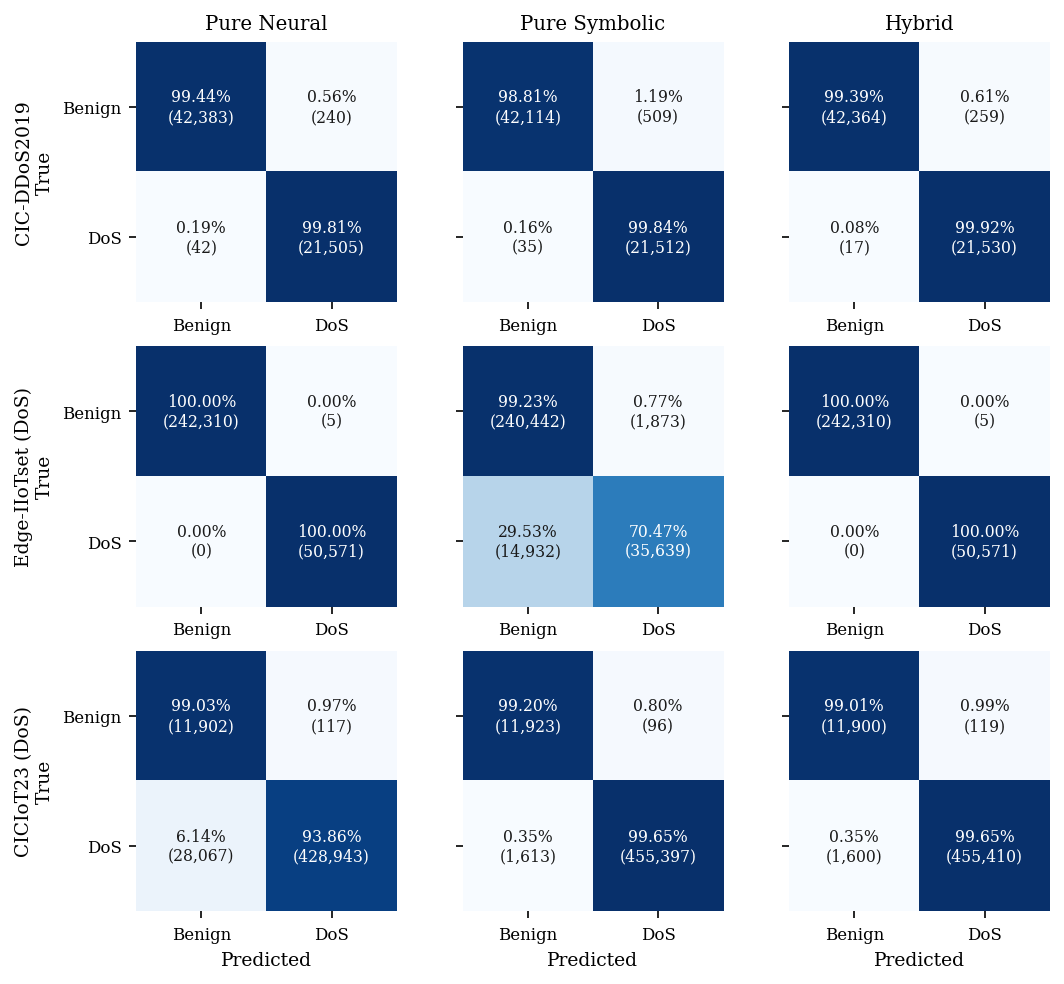

   saved results/figures/confusion_matrices.png / .pdf


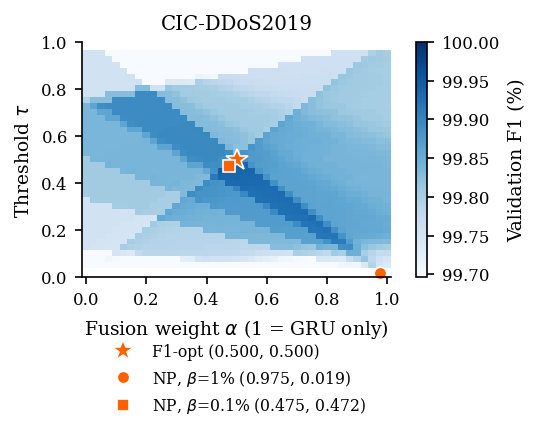

   saved results/figures/alpha_heatmap_cic_ddos.png / .pdf


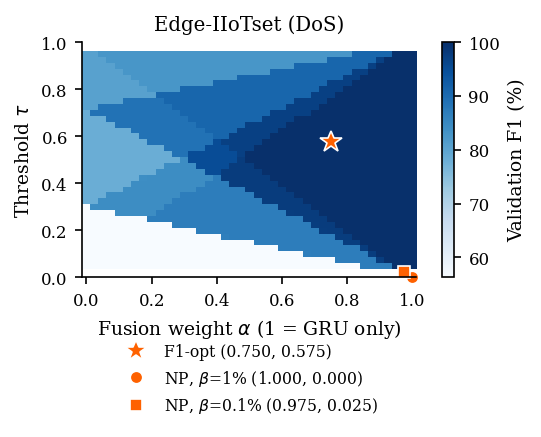

   saved results/figures/alpha_heatmap_edge_iot.png / .pdf


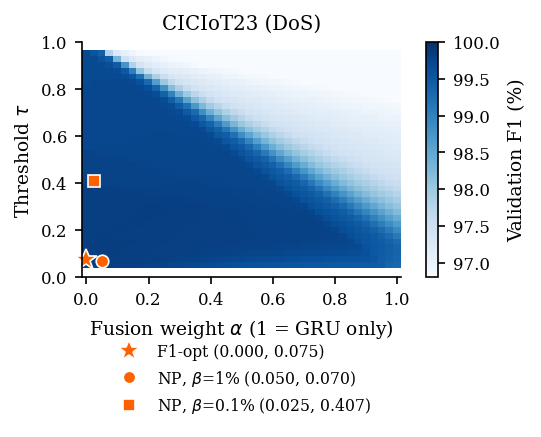

   saved results/figures/alpha_heatmap_ciciot23.png / .pdf


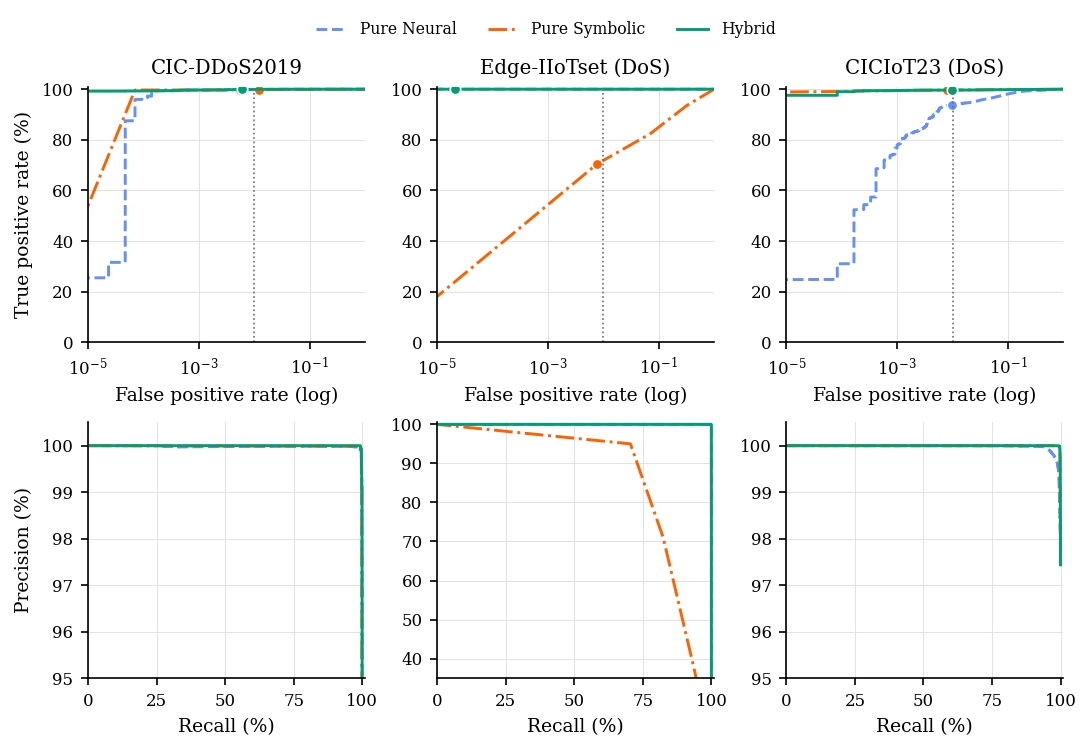

   saved results/figures/roc_pr_curves.png / .pdf


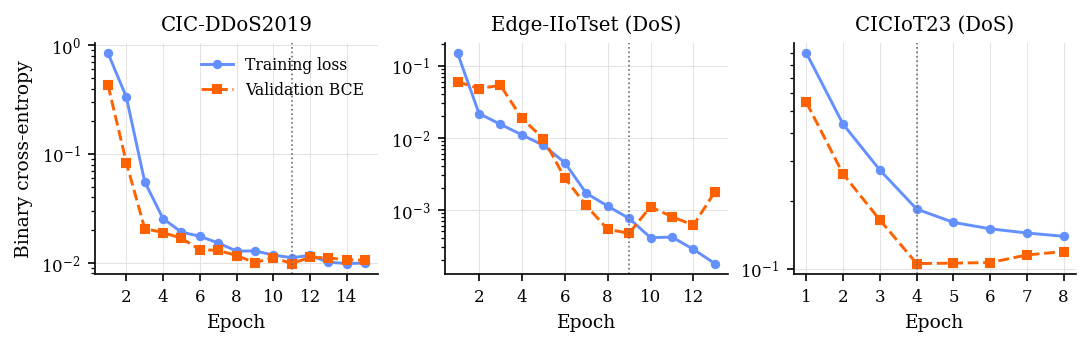

   saved results/figures/training_curves.png / .pdf


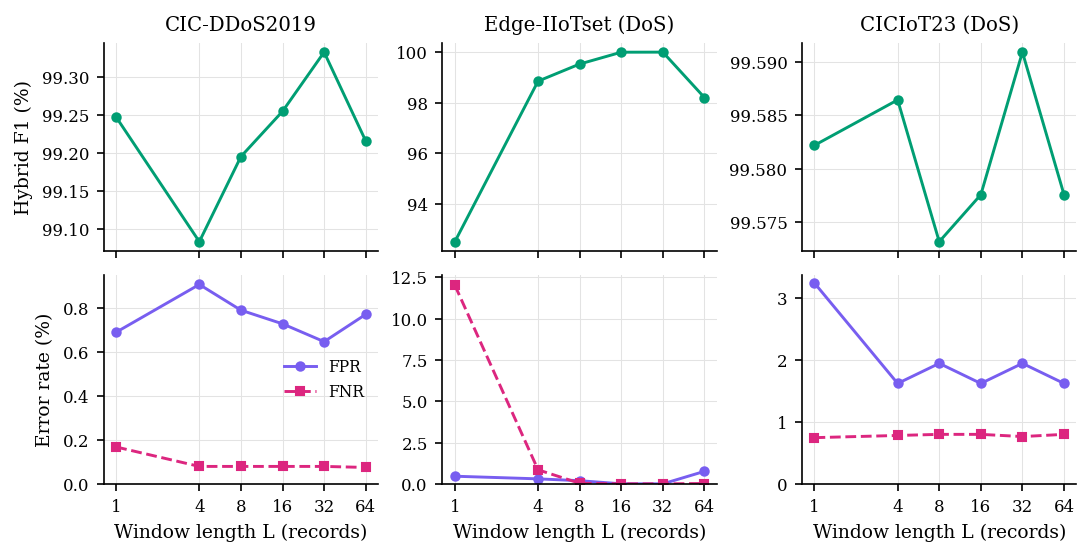

   saved results/figures/window_length.png / .pdf


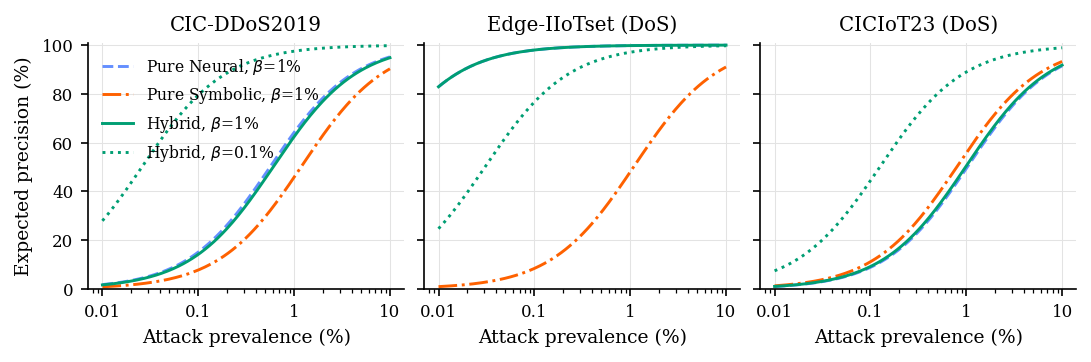

   saved results/figures/precision_vs_prevalence.png / .pdf


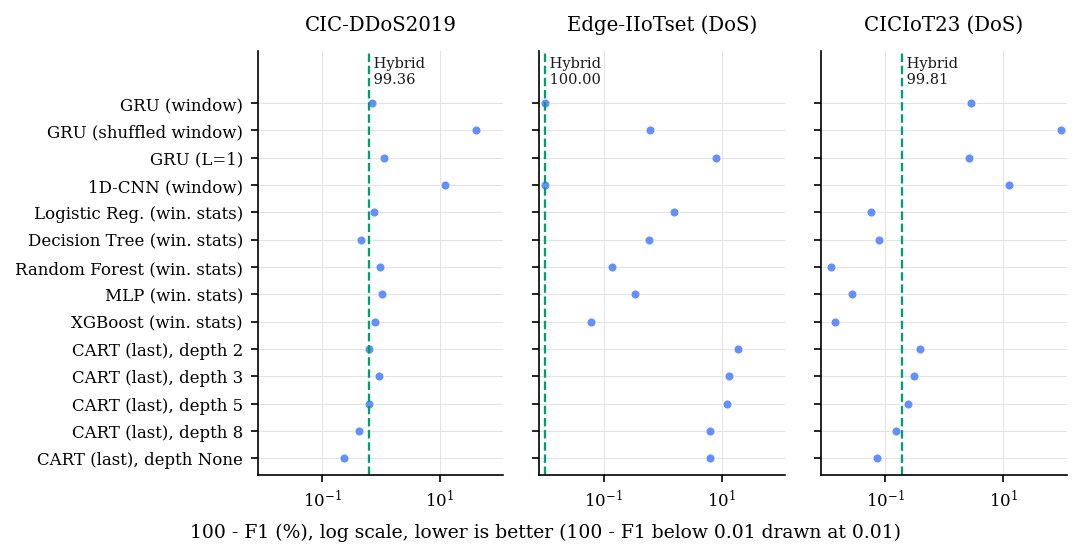

   saved results/figures/baselines.png / .pdf


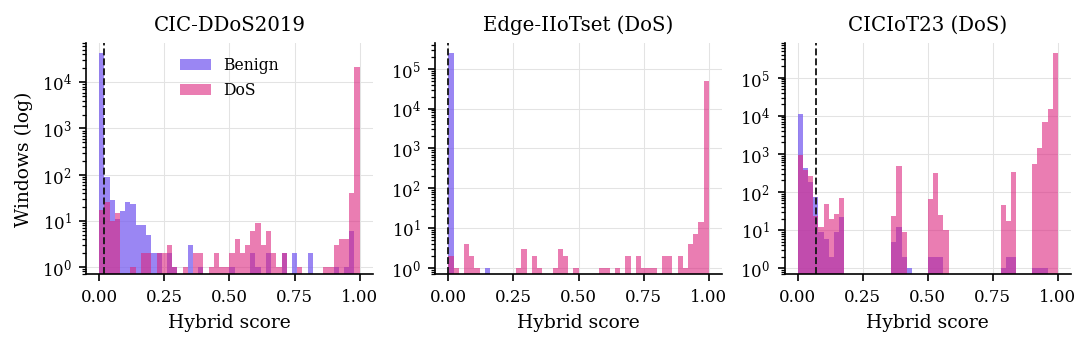

   saved results/figures/score_distributions.png / .pdf
CELL 21 complete


In [22]:
# CELL 21: Figures
print("CELL 21: Figures\n")
#   Every figure is drawn from the saved results (json and npz); nothing is retrained.
#   Output: results/figures/<name>.png (300 dpi) and <name>.pdf (vector, Type 42 fonts).
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import roc_curve, precision_recall_curve

matplotlib.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7.5,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#E3E3E3',
    'grid.linewidth': 0.5,
    'axes.axisbelow': True,
    'lines.linewidth': 1.4,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# IBM Colour-Blind Friendly Palette (same as the original figures)
CBF = {'Pure Neural': '#648FFF', 'Pure Symbolic': '#FE6100', 'Hybrid': '#009E73'}
LS = {'Pure Neural': '--', 'Pure Symbolic': '-.', 'Hybrid': '-'}
MODELS = (("gru", "Pure Neural"), ("tree", "Pure Symbolic"), ("hybrid", "Hybrid"))
DS_LABEL = {"cic_ddos": "CIC-DDoS2019", "edge_iot": "Edge-IIoTset (DoS)", "ciciot23": "CICIoT23 (DoS)"}
C_BENIGN, C_ATTACK = '#785EF0', '#DC267F'
FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
W2 = 7.16   # IEEE double-column width (in)
hk = f"NP{CFG['HEADLINE_BETA']}"
tag0 = f"time_blocked_f0_s{CFG['SEEDS'][0]}"


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)
    print(f"   saved {FIG / name}.png / .pdf")


def headline(ds):
    f = RES / ds / "runs" / f"{tag0}.json"
    if not f.exists(): return None, None
    R = json.load(open(f)); z = f.with_name(f.stem + "_scores.npz")
    return R, (np.load(z) if z.exists() else None)


DSS = [ds for ds in CFG["DATASETS"] if headline(ds)[0] is not None]

# Fig. 1: row-normalised confusion matrices at the headline operating point
fig, axes = plt.subplots(len(DSS), 3, figsize=(W2, 2.15 * len(DSS)), squeeze=False, constrained_layout=True)
for i, ds in enumerate(DSS):
    R, _ = headline(ds)
    for j, (m, lab) in enumerate(MODELS):
        t = R["test"][m][hk]
        cm = np.array([[t["tn"], t["fp"]], [t["fn"], t["tp"]]], float)
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax = axes[i, j]
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        ax.grid(False)
        for r in range(2):
            for c in range(2):
                ax.text(c, r, f"{cmn[r, c]*100:.2f}%\n({int(cm[r, c]):,})", ha="center", va="center", fontsize=7.5,
                        color="white" if cmn[r, c] > 0.6 else "#1A1A1A")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "DoS"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Benign", "DoS"] if j == 0 else ["", ""])
        if i == len(DSS) - 1: ax.set_xlabel("Predicted")
        if j == 0: ax.set_ylabel(f"{DS_LABEL[ds]}\nTrue")
        if i == 0: ax.set_title(lab)
        for sp in ax.spines.values(): sp.set_visible(False)
save(fig, "confusion_matrices")

# Fig. 2: validation F1 over (alpha, tau) with the selected operating points
for ds in DSS:
    R, d = headline(ds)
    if d is None: continue
    yv, sn, ss = d["yv"], d["sn_v"], d["ss_v"]
    A, T = CFG["ALPHA_GRID"], CFG["TAU_GRID_F1"]
    pos = yv == 1; F = np.zeros((len(T), len(A)))
    for j, a in enumerate(A):
        h = fuse(a, sn, ss)
        hp, hn = np.sort(h[pos]), np.sort(h[~pos])
        tp = len(hp) - np.searchsorted(hp, T.astype(np.float32), side="left")
        fp = len(hn) - np.searchsorted(hn, T.astype(np.float32), side="left")
        fn = len(hp) - tp
        F[:, j] = np.where(tp > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0)
    fig, ax = plt.subplots(figsize=(3.5, 2.8), constrained_layout=True)
    da, dtau = A[1] - A[0], T[1] - T[0]
    vmin = max(0.0, float(np.percentile(F, 10)))
    im = ax.imshow(F * 100, origin="lower", aspect="auto", cmap="Blues", vmin=vmin * 100, vmax=100,
                   extent=[A[0] - da / 2, A[-1] + da / 2, T[0] - dtau / 2, T[-1] + dtau / 2])
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax); cb.set_label("Validation F1 (%)")
    P_ = R["points"]["hybrid"]
    marks = (("F1", "F1-opt", "*", 11), (f"NP{CFG['HEADLINE_BETA']}", r"NP, $\beta$=1%", "o", 6),
             ("NP0.001", r"NP, $\beta$=0.1%", "s", 6))
    for k, lab, mk, ms in marks:
        if k in P_:
            ax.plot(P_[k]["alpha"], max(P_[k]["tau"], 0.0), mk, ms=ms, mfc=CBF["Pure Symbolic"], mec="white",
                    mew=0.8, ls="none", label=f"{lab} ({P_[k]['alpha']:.3f}, {P_[k]['tau']:.3f})", clip_on=False)
    ax.set_xlim(0 - da / 2, 1 + da / 2); ax.set_ylim(0, 1)
    ax.set_xlabel(r"Fusion weight $\alpha$ (1 = GRU only)"); ax.set_ylabel(r"Threshold $\tau$")
    ax.set_title(DS_LABEL[ds])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1, frameon=False)
    save(fig, f"alpha_heatmap_{ds}")

# Fig. 3: ROC (log FPR axis) and precision-recall curves on the test windows
fig, axes = plt.subplots(2, len(DSS), figsize=(W2, 4.6), squeeze=False, constrained_layout=True)
for j, ds in enumerate(DSS):
    R, d = headline(ds)
    if d is None: continue
    yt = d["yt"]
    for m, lab in MODELS:
        s = fuse(R["points"][m][hk]["alpha"], d["sn_t"], d["ss_t"])
        fpr, tpr, _ = roc_curve(yt, s); pr, rc, _ = precision_recall_curve(yt, s)
        t = R["test"][m][hk]
        axes[0, j].plot(np.maximum(fpr, 1e-6), tpr * 100, LS[lab], color=CBF[lab], label=lab)
        axes[0, j].plot(max(t["fpr"], 1e-6), t["rec"] * 100, "o", color=CBF[lab], ms=5, mec="white", mew=0.8)
        axes[1, j].plot(rc * 100, pr * 100, LS[lab], color=CBF[lab])
    ax = axes[0, j]
    ax.axvline(CFG["HEADLINE_BETA"], color="#6E6E6E", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xlim(1e-5, 1); ax.set_ylim(0, 101)
    ax.set_xlabel("False positive rate (log)"); ax.set_title(DS_LABEL[ds])
    axes[1, j].set_xlabel("Recall (%)"); axes[1, j].set_xlim(0, 101)
    lo = min(l.get_ydata()[np.asarray(l.get_xdata()) <= 99.0].min(initial=100) for l in axes[1, j].get_lines())
    axes[1, j].set_ylim(max(0, 5 * math.floor((lo - 1) / 5)), 100.5)
axes[0, 0].set_ylabel("True positive rate (%)"); axes[1, 0].set_ylabel("Precision (%)")
# AUC and AP values are in Table ml_baselines; dots mark the NP operating point, dotted line beta
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
save(fig, "roc_pr_curves")

# Fig. 4: GRU training curves (headline run, early stopping on validation BCE)
fig, axes = plt.subplots(1, len(DSS), figsize=(W2, 2.2), squeeze=False, constrained_layout=True)
for j, ds in enumerate(DSS):
    R, _ = headline(ds); h = pd.DataFrame(R["gru_training"]["history"]); ax = axes[0, j]
    ax.plot(h["epoch"], h["train_loss"], "-", color=CBF["Pure Neural"], marker="o", ms=3.5, label="Training loss")
    ax.plot(h["epoch"], h["val_bce"], "--", color=CBF["Pure Symbolic"], marker="s", ms=3.5, label="Validation BCE")
    b = h.loc[h["val_bce"].idxmin()]
    ax.axvline(b["epoch"], color="#6E6E6E", lw=0.8, ls=":")
    ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_title(DS_LABEL[ds])
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axes[0, 0].set_ylabel("Binary cross-entropy"); axes[0, 0].legend(frameon=False)
save(fig, "training_curves")

# Fig. 5: window-length sensitivity (same test windows for every L)
fig, axes = plt.subplots(2, len(DSS), figsize=(W2, 3.6), squeeze=False, sharex=True, constrained_layout=True)
for j, ds in enumerate(DSS):
    rows = []
    for L in CFG["L_SWEEP"]:
        f = RES / ds / "runs" / f"{tag0}_L{L}.json"
        if f.exists():
            t = json.load(open(f))["test"]["hybrid"][hk]; rows.append((L, t["f1"], t["fpr"], t["fnr"]))
    if not rows: continue
    r = np.array(rows, float)
    axes[0, j].plot(r[:, 0], r[:, 1] * 100, "-o", color=CBF["Hybrid"], ms=4)
    axes[1, j].plot(r[:, 0], r[:, 2] * 100, "-o", color=C_BENIGN, ms=4, label="FPR")
    axes[1, j].plot(r[:, 0], r[:, 3] * 100, "--s", color=C_ATTACK, ms=4, label="FNR")
    axes[0, j].set_title(DS_LABEL[ds]); axes[1, j].set_xscale("log", base=2)
    axes[1, j].set_xticks(r[:, 0]); axes[1, j].set_xticklabels([str(int(v)) for v in r[:, 0]])
    axes[1, j].set_xlabel("Window length L (records)")
    axes[1, j].set_ylim(bottom=0)
axes[0, 0].set_ylabel("Hybrid F1 (%)"); axes[1, 0].set_ylabel("Error rate (%)"); axes[1, 0].legend(frameon=False)
save(fig, "window_length")

# Fig. 6: expected precision against attack prevalence (analytical, test TPR/FPR)
fig, axes = plt.subplots(1, len(DSS), figsize=(W2, 2.3), squeeze=False, sharey=True, constrained_layout=True)
pis = np.logspace(-4, -1, 200)
for j, ds in enumerate(DSS):
    R, _ = headline(ds); ax = axes[0, j]
    curves = [(m, lab, hk, LS[lab], f"{lab}, " + r"$\beta$=1%") for m, lab in MODELS]
    curves.append(("hybrid", "Hybrid", "NP0.001", ":", r"Hybrid, $\beta$=0.1%"))
    for m, lab, k, ls, txt in curves:
        if k not in R["test"][m]: continue
        t = R["test"][m][k]
        prec = t["rec"] * pis / np.maximum(t["rec"] * pis + t["fpr"] * (1 - pis), 1e-12)
        ax.plot(pis * 100, prec * 100, ls, color=CBF[lab], label=txt)
    ax.set_xscale("log"); ax.set_xlabel("Attack prevalence (%)"); ax.set_title(DS_LABEL[ds]); ax.set_ylim(0, 101)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
axes[0, 0].set_ylabel("Expected precision (%)"); axes[0, 0].legend(frameon=False, loc="upper left")
save(fig, "precision_vs_prevalence")

# Fig. 7: baselines, 100 - F1 on a log axis (lower is better) at the same NP operating point
fig, axes = plt.subplots(1, len(DSS), figsize=(W2, 3.6), squeeze=False, sharey=True, constrained_layout=True)
labels_all = None
for j, ds in enumerate(DSS):
    f = RES / ds / "baselines" / f"time_blocked_s{CFG['SEEDS'][0]}.json"
    if not f.exists(): continue
    B_ = json.load(open(f)); labels = list(B_.keys())[::-1]
    labels_all = labels_all or labels
    err = [max(100 - B_[k]["np"]["f1"] * 100, 1e-2) if k in B_ else np.nan for k in labels_all]
    y = np.arange(len(labels_all)); ax = axes[0, j]
    ax.plot(err, y, "o", color=CBF["Pure Neural"], ms=4.5, mec="white", mew=0.6)
    R, _ = headline(ds)
    hy = max(100 - R["test"]["hybrid"][hk]["f1"] * 100, 1e-2)
    ax.axvline(hy, color=CBF["Hybrid"], ls="--", lw=1.1)
    ax.text(hy, len(labels_all) - 0.4, f" Hybrid\n {R['test']['hybrid'][hk]['f1']*100:.2f}", color="#1A1A1A",
            fontsize=7, va="bottom", ha="left")
    ax.set_xscale("log"); ax.set_xlim(8e-3, 120); ax.set_ylim(-0.6, len(labels_all) + 0.9)
    ax.set_title(DS_LABEL[ds], pad=10)
if labels_all:
    axes[0, 0].set_yticks(np.arange(len(labels_all))); axes[0, 0].set_yticklabels(labels_all)
    fig.supxlabel("100 - F1 (%), log scale, lower is better (100 - F1 below 0.01 drawn at 0.01)", fontsize=9)
save(fig, "baselines")

# Fig. 8: hybrid score distributions on the test windows
fig, axes = plt.subplots(1, len(DSS), figsize=(W2, 2.2), squeeze=False, constrained_layout=True)
for j, ds in enumerate(DSS):
    R, d = headline(ds)
    if d is None: continue
    p = R["points"]["hybrid"][hk]; s = fuse(p["alpha"], d["sn_t"], d["ss_t"]); yt = d["yt"]; ax = axes[0, j]
    bins = np.linspace(0, 1, 51)
    ax.hist(s[yt == 0], bins, color=C_BENIGN, alpha=0.75, label="Benign", log=True)
    ax.hist(s[yt == 1], bins, color=C_ATTACK, alpha=0.6, label="DoS", log=True, histtype="stepfilled")
    ax.axvline(p["tau"], color="#1A1A1A", lw=0.9, ls="--")
    ax.set_xlabel("Hybrid score"); ax.set_title(DS_LABEL[ds])
    ax.set_ylim(bottom=0.7)
axes[0, 0].set_ylabel("Windows (log)"); axes[0, 0].legend(frameon=False, loc="upper center")
save(fig, "score_distributions")

print("CELL 21 complete")